# Laboratorio 3 - Clasificación

**Curso:** ISIS2611 - Aprendizaje de Máquina **Caso:** Ruta Alpes

**Integrantes:** Samuel Andres Molina Luna, Daniel Esteban Pardo Pardo

Ruta Alpes es una aplicación de asistencia de conducción que recomienda cupones a los conductores mientras se desplazan. Este laboratorio construye modelos de clasificación para anticipar si un conductor **aceptará** (`acepta_cupon` = Sí / No) un cupón de **Cafetería** o de **Restaurante(<20)**, y evalúa los riesgos de sesgo de personalizar ofertas con datos demográficos.

**Objetivos**
* Comparar regresión logística, árboles de decisión y Random Forest para cada tipo de cupón.
* Evaluar si el desbalance de clases afecta el desempeño y si una técnica de balanceo lo mejora.
* Reconocer posibles sesgos al usar variables demográficas para personalización.
* Comunicar los resultados y sustentar las decisiones metodológicas.

## 1. Carga de datos y librerias

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, precision_score, recall_score, f1_score

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

### Cargar datos a dataframe

In [2]:
data = pd.read_excel('data/Lab3_Datos.xlsx')
df_Base = data.copy()
df_Base.shape
df_Base.head()

,destino,acompanante,clima,temperatura,hora,cupon,vigencia_cupon,genero,edad,estado_civil,...,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_5min,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,direccion_opuesta,acepta_cupon
0,Sin lugar urgente,Solo,Soleado,55,2:00 p.m.,Restaurante(<20),1 día,Femenino,21,Unión libre,...,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No,Sí,Sí
1,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Cafetería,2 horas,Femenino,21,Unión libre,...,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No,Sí,No
2,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Comida para llevar,2 horas,Femenino,21,Unión libre,...,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,Sí
3,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,2 horas,Femenino,21,Unión libre,...,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,No
4,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,1 día,Femenino,21,Unión libre,...,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,No


In [3]:
# Dataset de prueba (sin etiqueta)
df_test = pd.read_excel('data/Lab3_datos_Prueba.xlsx')
df_test.head()

,destino,acompanante,clima,temperatura,hora,cupon,vigencia_cupon,genero,edad,estado_civil,...,frecuencia_bar,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_5min,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,direccion_opuesta
0,Trabajo,Solo,Soleado,55,7:00 a.m.,Cafetería,2 horas,Femenino,50 o más,Divorciado(a),...,1 a 3,4 a 8,4 a 8,4 a 8,menos de 1,Sí,Sí,No,No,Sí
1,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Cafetería,2 horas,Femenino,31,Unión libre,...,menos de 1,1 a 3,más de 8,4 a 8,1 a 3,Sí,No,No,No,Sí
2,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,2 horas,Femenino,31,Soltero(a),...,menos de 1,1 a 3,4 a 8,más de 8,menos de 1,Sí,Sí,No,No,Sí
3,Sin lugar urgente,Pareja,Soleado,80,10:00 a.m.,Cafetería,2 horas,Masculino,50 o más,Casado(a),...,nunca,más de 8,nunca,4 a 8,menos de 1,Sí,No,No,No,Sí
4,Sin lugar urgente,Amigo(s),Soleado,80,6:00 p.m.,Restaurante(<20),2 horas,Femenino,26,Soltero(a),...,1 a 3,menos de 1,4 a 8,menos de 1,4 a 8,Sí,Sí,No,No,Sí


# 2. Exploración de los datos

Aqui se analizan por separado los dos subconjuntos del caso que son los registros del cupon **Cafeteria** y los del cupon **Restaurante(<20)**. El objetivo es entender la variable objetivo `acepta_cupon` y diagnosticar la calidad de los datos.

**2.1 Visión general**

Se revisa el tamaño del conjunto, el tipo de dato de cada columna y un resumen estadistico para tener una primera idea de las variables.

In [4]:
print(df_Base.shape)
df_Base.dtypes

(12664, 26)


destino                            object
acompanante                        object
clima                              object
temperatura                         int64
hora                               object
cupon                              object
vigencia_cupon                     object
genero                             object
edad                               object
estado_civil                       object
tiene_hijos                        object
educacion                          object
ocupacion                          object
ingreso                            object
vehiculo                           object
frecuencia_bar                     object
frecuencia_cafeteria               object
frecuencia_comida_para_llevar      object
frecuencia_restaurante_menos_20    object
frecuencia_restaurante_20_a_50     object
tiempo_cupon_mayor_5min            object
tiempo_cupon_mayor_15min           object
tiempo_cupon_mayor_25min           object
misma_direccion                   

In [5]:
df_Base.describe(include='all')

,destino,acompanante,clima,temperatura,hora,cupon,vigencia_cupon,genero,edad,estado_civil,...,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_5min,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,direccion_opuesta,acepta_cupon
count,12664,12664,12664,12664.000000,12664,12664,12664,12664,12664,12664,...,12447,12513,12534,12475,12664,12664,12664,12664,12664,12664
unique,3,4,3,NaN,5,5,2,2,8,5,...,5,5,5,5,1,2,2,2,2,2
top,Sin lugar urgente,Solo,Soleado,NaN,6:00 p.m.,Cafetería,1 día,Femenino,21,Casado(a),...,menos de 1,1 a 3,1 a 3,menos de 1,Sí,Sí,No,No,Sí,Sí
freq,6270,7296,10052,NaN,3224,3986,7081,6501,2652,5092,...,3378,4665,5368,6066,12664,7113,11153,9944,9944,7196
mean,NaN,NaN,NaN,63.287271,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,19.158130,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,30.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,80.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,80.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2.2 Calidad de datos y separacion por tipo de cupon y distribucion de `acepta_cupon`

El enunciado pide trabajar solo con los cupones Cafeteria y Restaurante(<20) por lo que se separa cada subconjunto y se mira cuantos registros tiene y que proporcion acepta el cupon, para saber si las clases estan balanceadas.

In [6]:
cafe = df_Base[df_Base['cupon'] == 'Cafetería'].copy()
rest = df_Base[df_Base['cupon'] == 'Restaurante(<20)'].copy()

for nombre, s in [('Cafetería', cafe), ('Restaurante(<20)', rest)]:
    print(nombre, s.shape)
    print(s['acepta_cupon'].value_counts())
    print(s['acepta_cupon'].value_counts(normalize=True).round(3), '\n')

Cafetería (3986, 26)
acepta_cupon
No    1997
Sí    1989
Name: count, dtype: int64
acepta_cupon
No    0.501
Sí    0.499
Name: proportion, dtype: float64 

Restaurante(<20) (2776, 26)
acepta_cupon
Sí    1962
No     814
Name: count, dtype: int64
acepta_cupon
Sí    0.707
No    0.293
Name: proportion, dtype: float64 



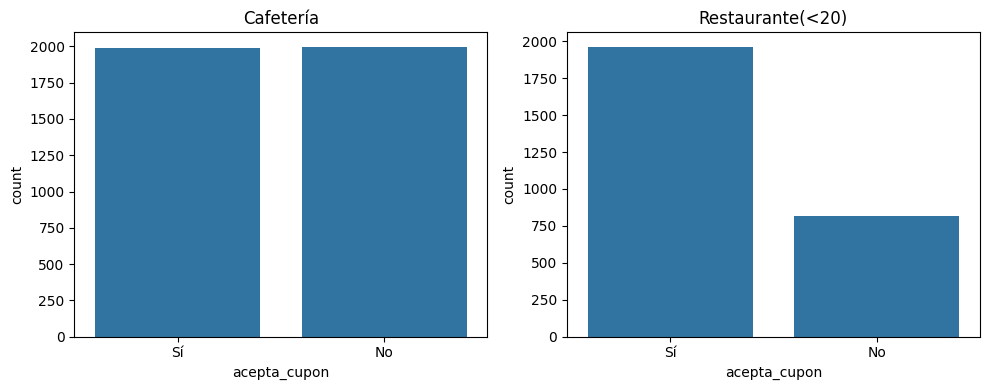

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (nombre, s) in zip(axes, [('Cafetería', cafe), ('Restaurante(<20)', rest)]):
    sns.countplot(data=s, x='acepta_cupon', order=['Sí', 'No'], ax=ax)
    ax.set_title(nombre)
plt.tight_layout()
plt.show()

Aqui analizamos lo siguiente:
- **Cafetería** (3.986 registros): las clases estan practicamente balanceadas con 1.989 "Si" que es un 49,9 % y 1.997 "No" con 50,1 %. No se necesita balanceo y la exactitud es una metrica razonable, aunque se reportaran tambien precisión, recall y F1.
- **Restaurante(<20)** (2.776 registros): hay un desbalance moderado, con 1.962 "Sí" (70,7 %) y 814 "No" (29,3 %). La clase minoritaria es "No" que son quienes rechazan el cupon.
- **Implicación para el modelado:** en Restaurante(<20), un modelo que prediga siempre "Si" obtendria 70,7 % de accuracy sin aprender nada, es por esto que la accuracy engaña y se debe evaluar con F1 y con el recall de la clase minoritaria.

**2.3 Valores nulos**

Se calcula la cantidad y el porcentaje de valores nulos por columna en cada subconjunto (Cafeteria y Restaurante(<20)).

In [8]:
nulos = pd.DataFrame({
    'Cafetería (n)': cafe.isna().sum(),
    'Cafetería (%)': (cafe.isna().mean() * 100).round(2),
    'Restaurante(<20) (n)': rest.isna().sum(),
    'Restaurante(<20) (%)': (rest.isna().mean() * 100).round(2),
})
nulos[(nulos['Cafetería (n)'] > 0) | (nulos['Restaurante(<20) (n)'] > 0)]

,Cafetería (n),Cafetería (%),Restaurante(<20) (n),Restaurante(<20) (%)
vehiculo,3949,99.07,2751,99.10
frecuencia_bar,37,0.93,23,0.83
frecuencia_cafeteria,72,1.81,47,1.69
frecuencia_comida_para_llevar,57,1.43,34,1.22
frecuencia_restaurante_menos_20,50,1.25,27,0.97
frecuencia_restaurante_20_a_50,55,1.38,43,1.55


Vemos que **`vehiculo`** tiene un 99 % de valores nulos en ambos subconjuntos (3.949 de 3.986 en Cafeteria y 2.751 de 2.776 en Restaurante(<20)). como tiene tan pocos datos no es posible imputarla de forma confiable, y en el archivo de prueba tambien esta vacia, asi que no aportaria nada al modelo. **Las cinco variables de frecuencia** tienen pocos nulos, entre 0,83 % y 1,81 %. Con esta proporcion no se justifica eliminar filas por lo que se imputaran con la moda dentro del Pipeline. Ninguna otra variable presenta valores nulos incluida la variable objetivo `acepta_cupon`, por lo que no hay registros sin etiqueta que descartar.

**2.4 Estadísticas descriptivas**

Se resumen las variables del conjunto completo (12.664 registros antes de separar por cupon). Primero la unica variable numerica `temperatura` y luego las variables categoricas, donde interesa el número de categorías (`unique`) y el valor más frecuente (`top`, `freq`).

In [9]:
df_Base.describe()

,temperatura
count,12664.000000
mean,63.287271
std,19.158130
min,30.000000
25%,55.000000
50%,80.000000
75%,80.000000
max,80.000000


In [10]:
df_Base.describe(exclude='number')

,destino,acompanante,clima,hora,cupon,vigencia_cupon,genero,edad,estado_civil,tiene_hijos,...,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_5min,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,direccion_opuesta,acepta_cupon
count,12664,12664,12664,12664,12664,12664,12664,12664,12664,12664,...,12447,12513,12534,12475,12664,12664,12664,12664,12664,12664
unique,3,4,3,5,5,2,2,8,5,2,...,5,5,5,5,1,2,2,2,2,2
top,Sin lugar urgente,Solo,Soleado,6:00 p.m.,Cafetería,1 día,Femenino,21,Casado(a),No,...,menos de 1,1 a 3,1 a 3,menos de 1,Sí,Sí,No,No,Sí,Sí
freq,6270,7296,10052,3224,3986,7081,6501,2652,5092,7421,...,3378,4665,5368,6066,12664,7113,11153,9944,9944,7196


- **`temperatura`** es la unica variable numerica y solo toma tres valores 30, 55 y 80 °F, con media de 63,28. En la practica se comporta como una variable categorica ordenad y no como una medicion continua.
- **`vehiculo`** tiene solo 108 registros no nulos de 12.664 asi como lo vimos anteriormente.
- **`tiempo_cupon_mayor_5min`** tiene un unico valor ("Sí") en todos los registros por lo que es constante y no aporta informacion.
- **`misma_direccion` y `direccion_opuesta`** tienen la misma frecuencia en su valor mas comun que es 9.944, lo que sugiere que son complementarias.
- **`ocupacion`** tiene 25 categorias, la variable de mayor cardinalidad
- **`edad`** (8 niveles), **`ingreso`** (9) y **`educacion`** (6) son categorias con un orden natural y `hora` (5 niveles) y las variables `frecuencia_*` también lo tienen, por lo que se codificaran de forma ordinal.
- **`cupon`** tiene 5 categorias en el conjunto completo aunque en el lab se trabaja solo con Cafeteria (3.986 registros) y Restaurante(<20) (2.776).

**2.5 Duplicados**

Se revisa si existen filas completamente identicas tanto en el conjunto completo como en cada subconjunto.

In [11]:
print('Duplicados exactos en el conjunto completo:', df_Base.duplicated().sum())
for nombre, s in [('Cafetería', cafe), ('Restaurante(<20)', rest)]:
    print(f'{nombre}: {s.duplicated().sum()} de {len(s)} filas ({s.duplicated().mean()*100:.2f} %)')

Duplicados exactos en el conjunto completo: 74
Cafetería: 7 de 3986 filas (0.18 %)
Restaurante(<20): 7 de 2776 filas (0.25 %)


El conjunto completo tiene 74 filas duplicadas exactas. En cada subconjunto hay 7 lo cual es una proporcion muy pequeña, tambien los datos no incluyen un identificador de registro por lo que no es posible saber si un duplicado es una copia accidental o dos conductores distintos con exactamente las mismas respuestas. Como el efecto sobre el tamaño del conjunto es minimo y se evita el riesgo de fuga entre entrenamiento y prueba se eliminaran en la etapa de preparacion.

**2.6 Relación de las variables explicativas con `acepta_cupon`**

Para identificar qué variables parecen mas relacionadas con la aceptación del cupon se cruza cada variable con `acepta_cupon` mediante tablas de contingencia normalizadas por fila. Asi se obtiene para cada categoria el porcentaje de conductores que aceptan y que rechazan lo cual permite comparar categorias aunque tengan distinto numero de registros. Se hace por separado en Cafeteria y en Restaurante(<20). Se revisan por grupos: contexto del viaje, perfil del conductor y habitos de consumo.

In [12]:
orden_hora = ['7:00 a.m.', '10:00 a.m.', '2:00 p.m.', '6:00 p.m.', '10:00 p.m.']

for col in ['destino', 'acompanante', 'clima', 'hora', 'vigencia_cupon']:
    for nombre, s in [('Cafetería', cafe), ('Restaurante(<20)', rest)]:
        tabla = pd.crosstab(s[col], s['acepta_cupon'], normalize='index')
        if col == 'hora':
            tabla = tabla.reindex(orden_hora)
        print(f'{col} - {nombre}')
        print(tabla.round(2), '\n')

destino - Cafetería
acepta_cupon         No    Sí
destino                      
Casa               0.64  0.36
Sin lugar urgente  0.42  0.58
Trabajo            0.55  0.45 

destino - Restaurante(<20)
acepta_cupon         No    Sí
destino                      
Casa               0.44  0.56
Sin lugar urgente  0.21  0.79
Trabajo            0.42  0.58 

acompanante - Cafetería
acepta_cupon    No    Sí
acompanante             
Amigo(s)      0.40  0.60
Hijo(s)       0.52  0.48
Pareja        0.43  0.57
Solo          0.56  0.44 

acompanante - Restaurante(<20)
acepta_cupon    No    Sí
acompanante             
Amigo(s)      0.20  0.80
Hijo(s)       0.28  0.72
Pareja        0.23  0.77
Solo          0.36  0.64 

clima - Cafetería
acepta_cupon    No    Sí
clima                   
Lluvioso      0.48  0.52
Nevado        0.57  0.43
Soleado       0.50  0.50 

clima - Restaurante(<20)
acepta_cupon    No    Sí
clima                   
Lluvioso      0.61  0.39
Nevado        0.51  0.49
Soleado       0.23  

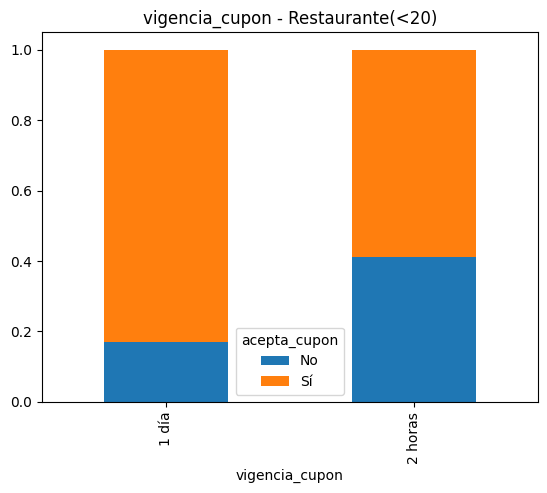

In [13]:
tabla.plot(kind='bar', stacked=True, title=f'{col} - {nombre}')
plt.show()

**2.6.2 Perfil del conductor**

Aqui vemos las variables demograficas del conductor como genero, edad, estado civil, si tiene hijos, nivel educativo e ingreso. Las que tienen un orden natural como por ejemplo edad, educación, ingreso se muestran en ese orden.

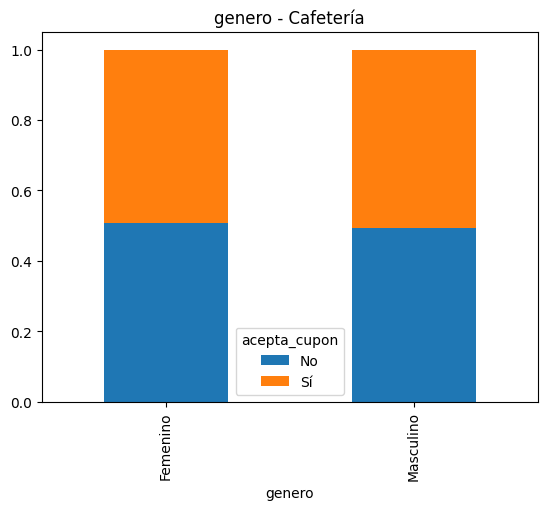

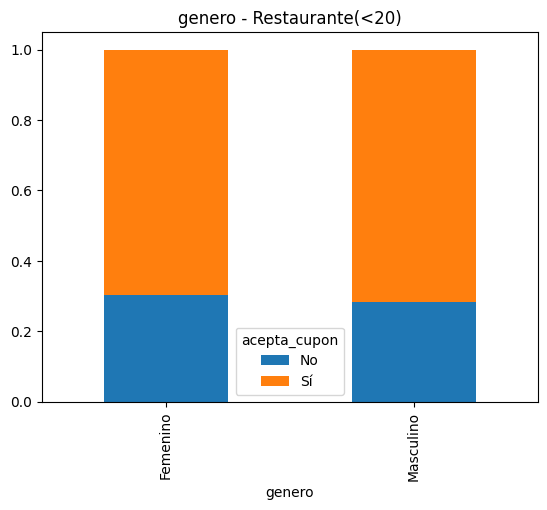

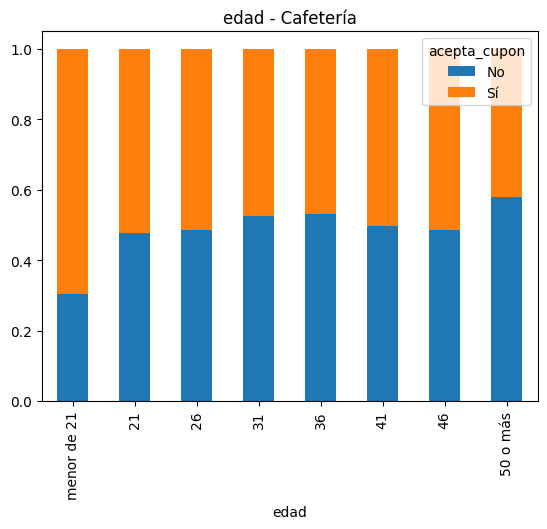

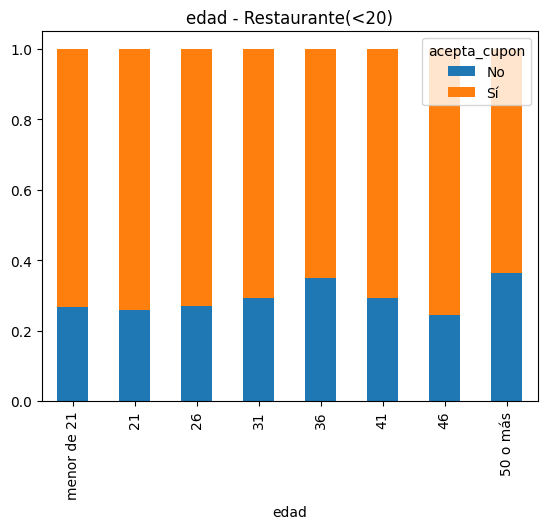

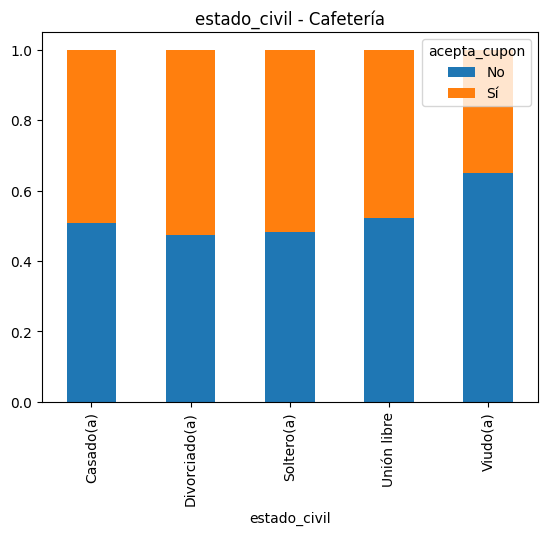

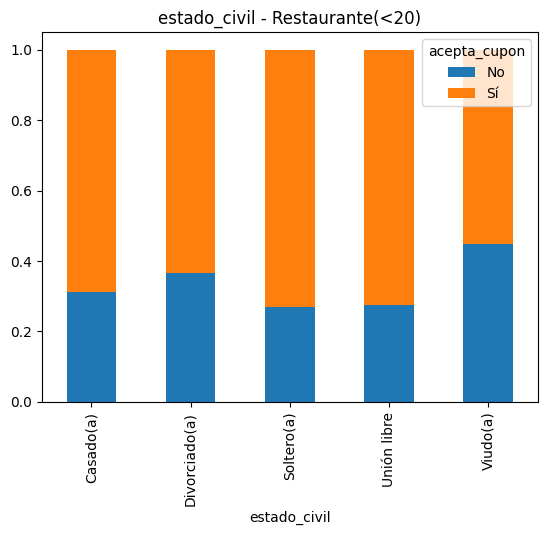

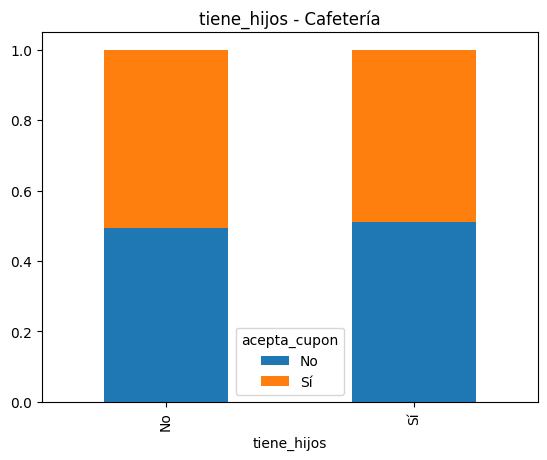

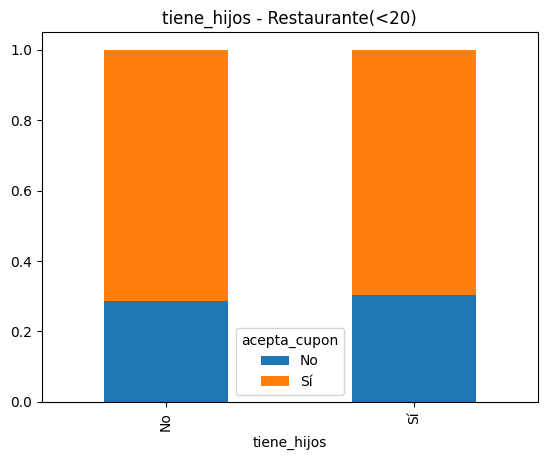

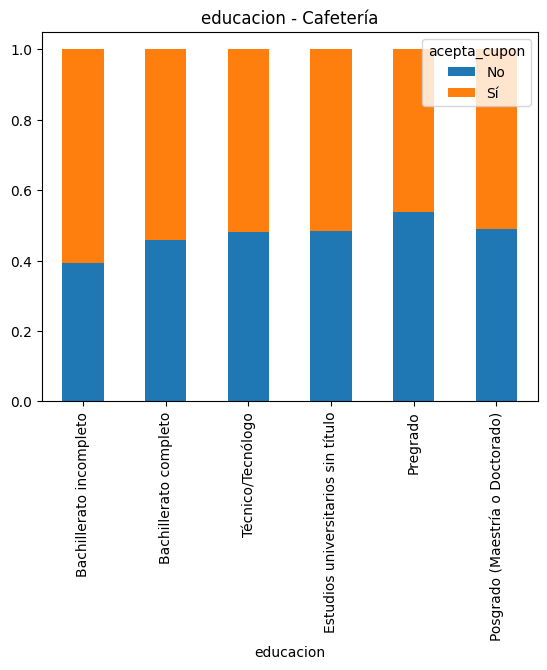

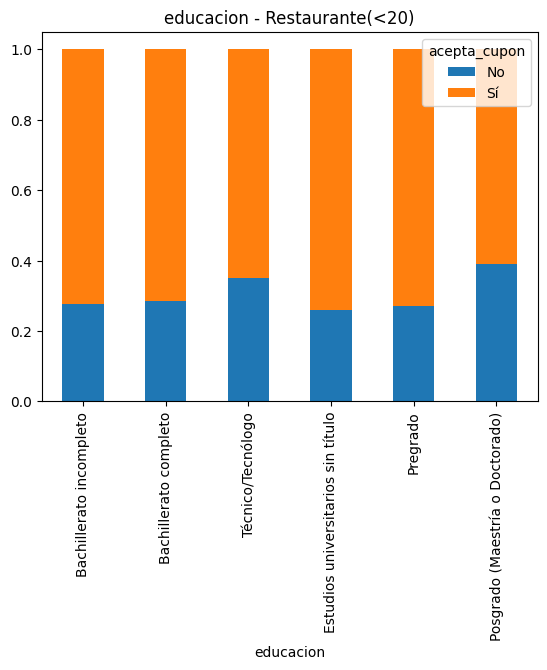

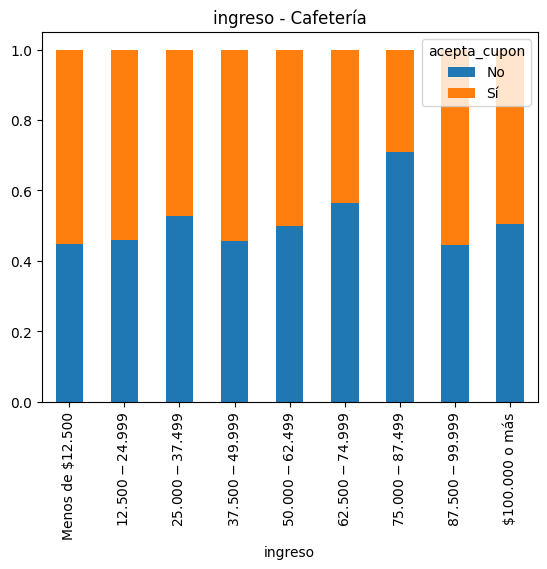

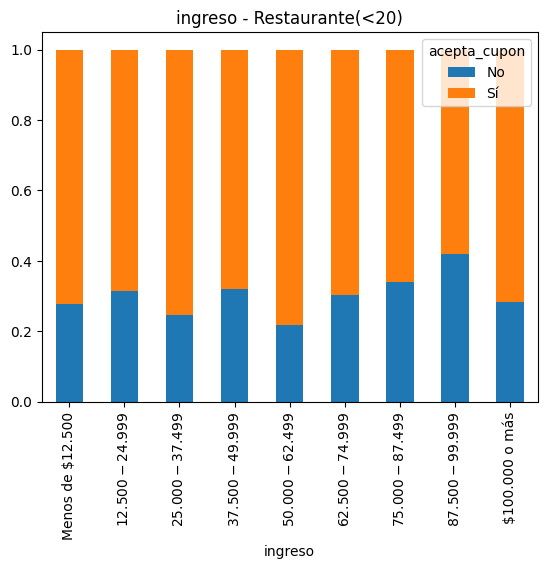

In [14]:
orden_edad = ['menor de 21', '21', '26', '31', '36', '41', '46', '50 o más']
orden_educacion = ['Bachillerato incompleto', 'Bachillerato completo', 'Técnico/Tecnólogo',
                   'Estudios universitarios sin título', 'Pregrado', 'Posgrado (Maestría o Doctorado)']
orden_ingreso = ['Menos de $12.500', '$12.500 - $24.999', '$25.000 - $37.499', '$37.500 - $49.999',
                 '$50.000 - $62.499', '$62.500 - $74.999', '$75.000 - $87.499',
                 '$87.500 - $99.999', '$100.000 o más']
ordenes = {'edad': orden_edad, 'educacion': orden_educacion, 'ingreso': orden_ingreso}

for col in ['genero', 'edad', 'estado_civil', 'tiene_hijos', 'educacion', 'ingreso']:
    for nombre, s in [('Cafetería', cafe), ('Restaurante(<20)', rest)]:
        tabla = pd.crosstab(s[col], s['acepta_cupon'], normalize='index')
        if col in ordenes:
            tabla = tabla.reindex(ordenes[col])
        tabla.plot(kind='bar', stacked=True, title=f'{col} - {nombre}')
        plt.show()

In [15]:
for nombre, s in [('Cafetería', cafe), ('Restaurante(<20)', rest)]:
    tabla = pd.crosstab(s['ocupacion'], s['acepta_cupon'], normalize='index')['Sí'].sort_values()
    print(nombre)
    print(tabla.round(2), '\n')

Cafetería
ocupacion
Servicios Comunitarios y Sociales                    0.35
Producción                                           0.36
Área Legal                                           0.38
Ventas y afines                                      0.39
Jubilado(a)                                          0.40
Apoyo Administrativo y de Oficina                    0.43
Educación, Formación y Bibliotecología               0.44
Preparación y Servicio de Alimentos                  0.45
Servicios de Protección y Seguridad                  0.45
Gerencia                                             0.46
Ciencias Naturales y Sociales                        0.48
Construcción y Extracción                            0.48
Negocios y Finanzas                                  0.48
Cuidado Personal y Servicios                         0.50
Computación y Matemáticas                            0.50
Artes, Diseño, Entretenimiento, Deportes y Medios    0.51
Desempleado(a)                                      

Se muestran diferencias menores que las del contexto del viaje ya que el genero y el hecho de tener hijos casi no cambian la aceptacion por lo que no nos dan tanta informacion por si solas. La edad si tiene un efecto en cafeteria donde los menores de 21 años aceptan mas (70 %) y los de 50 años o mas menos con un 42 %, mientras que en restaurante(<20) la variacion es pequeña entre 64 % y 76 % y sin una tendencia clara. 

En el estado civil los viudos aceptan menos en ambos cupones con 35 % en cafeteria y 55 % en restaurante(<20), aunque se trata de una categoria pequeña y la diferencia debe tenerse en cuenta, el nivel educativo y el ingreso presentan diferencias moderadas y sin un patron en donde crezca o decrezca de forma constante y se ve en cafeteria donde la aceptacion no sube ni baja de manera constante con el ingreso y llega a un mínimo de 29 % en el rango 75.000 a 87.499. 

Ya por ulitmo la ocupacion es la variable demografica con mas variacion donde en cafeteria va de cerca de 35 % en servicios comunitarios y sociales a cerca de 74 % en profesionales y tecnicos de la salud pero tiene 25 categorías y algunas cuentan con muy pocos registros por ejemplo, 11 en limpieza y mantenimiento de edificios en cafeteria.

**2.6.3 Habitos de consumo y caracteristicas del cupon**

Se revisa la frecuencia con la que el conductor visita distintos tipos de establecimientos (frecuencia) y las variables que describen que tan lejos y en que direccion queda el lugar del cupon (`misma_direccion`, `tiempo_cupon_mayor_15min`, `tiempo_cupon_mayor_25min`).

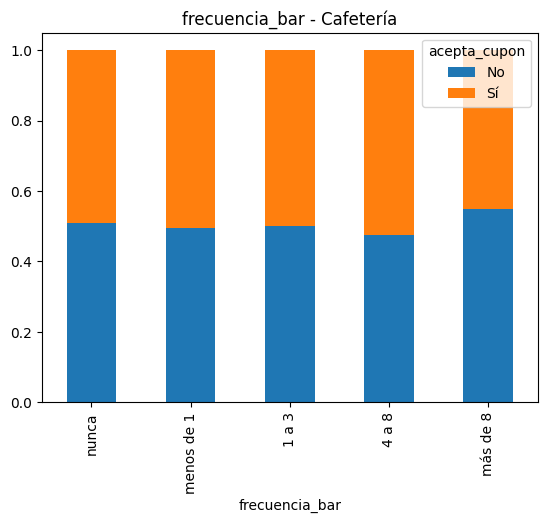

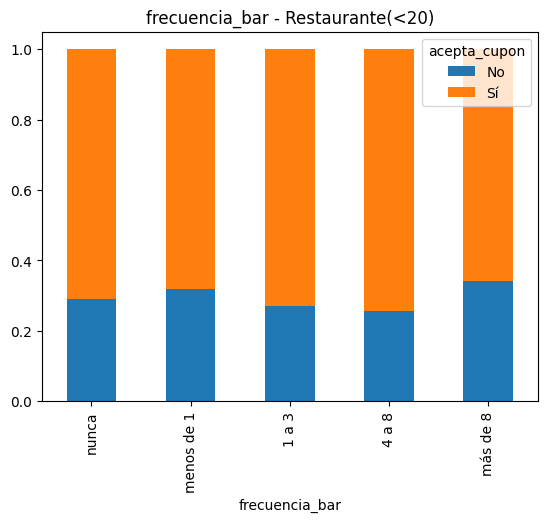

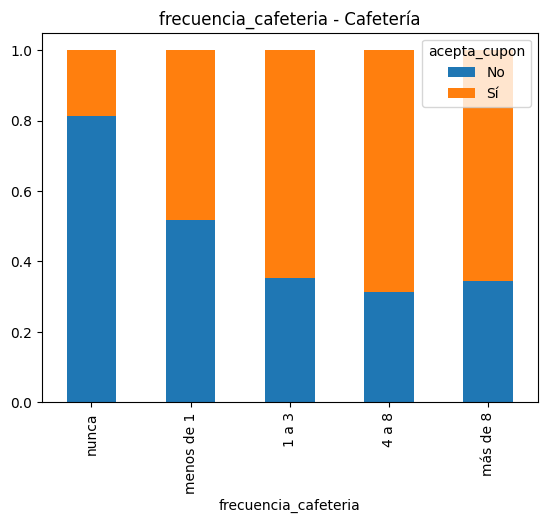

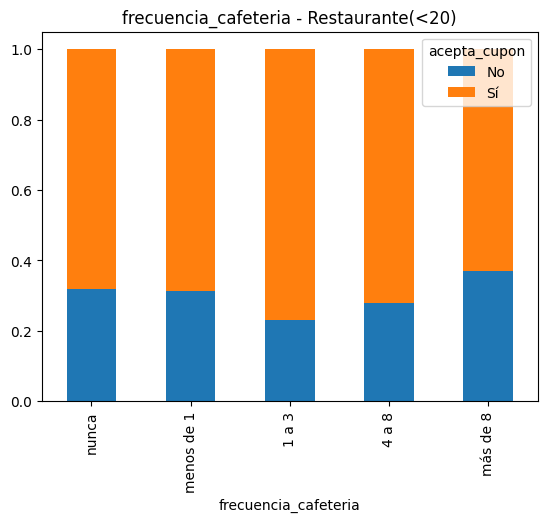

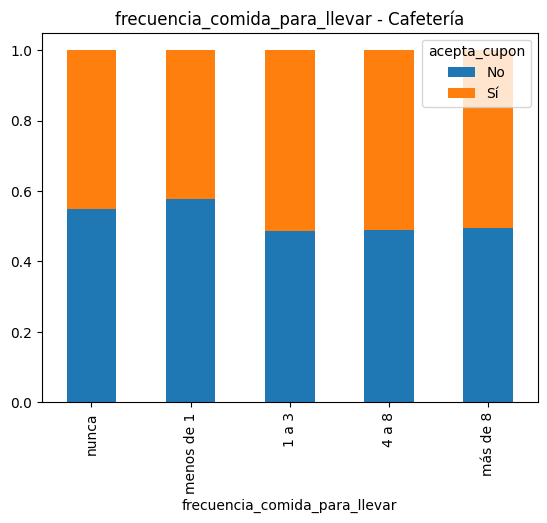

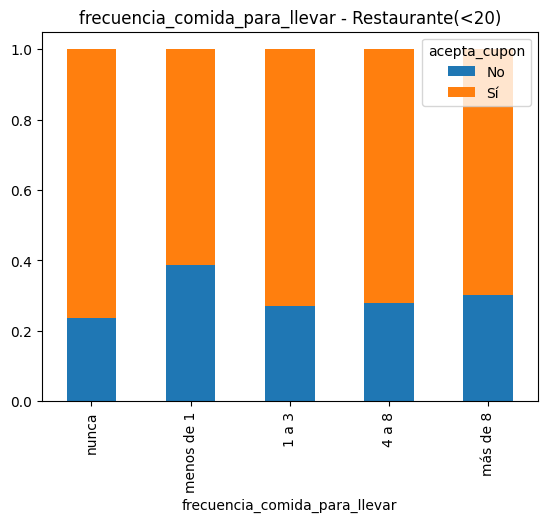

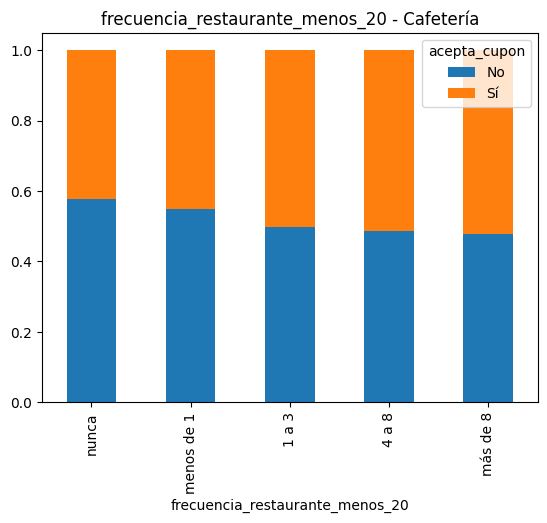

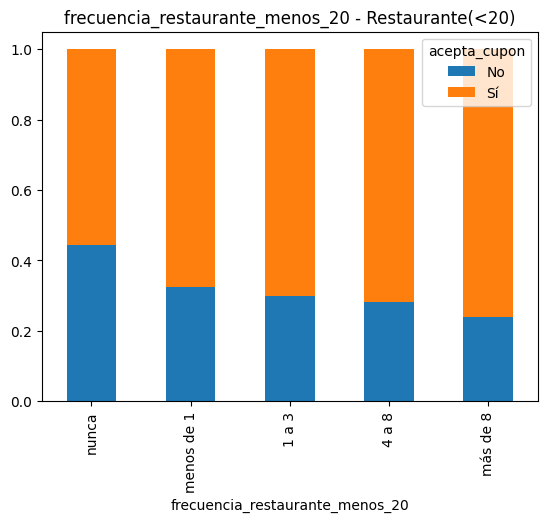

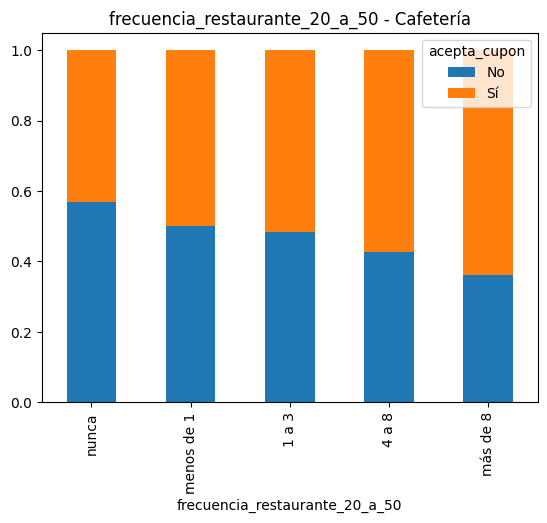

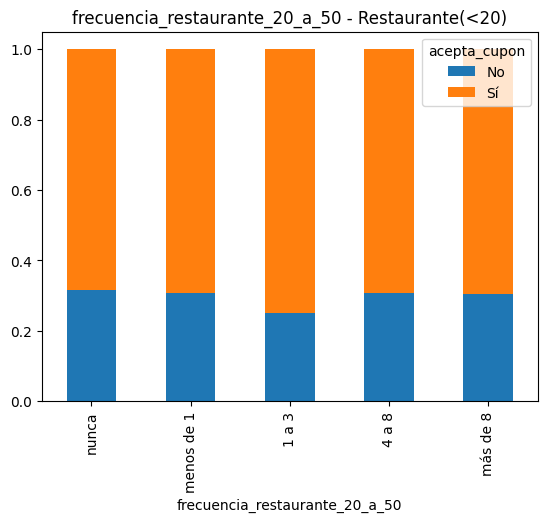

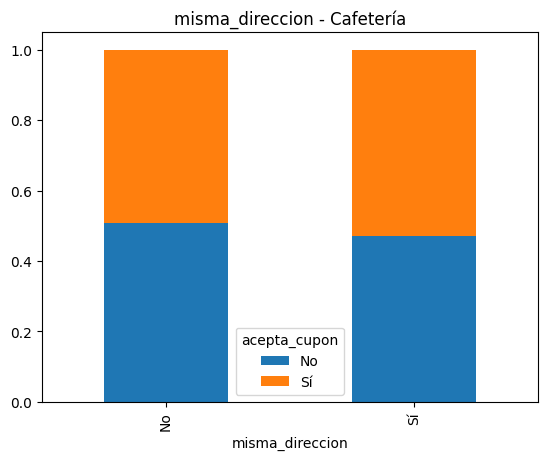

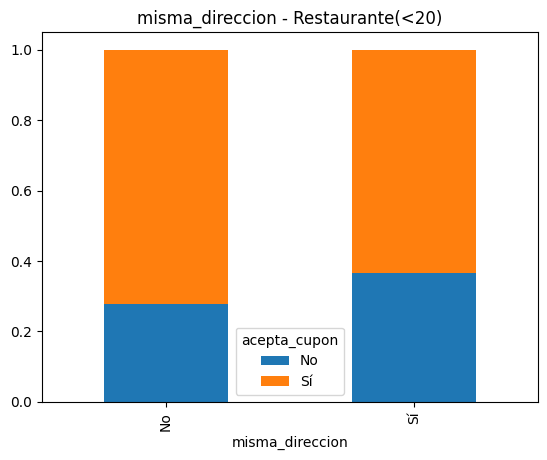

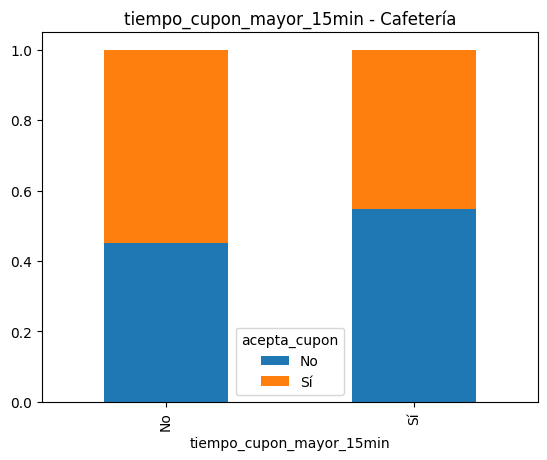

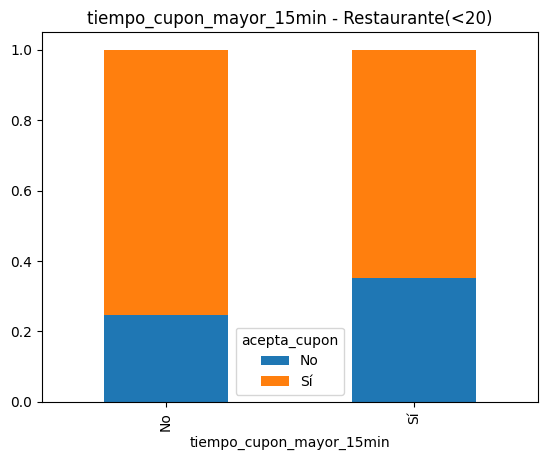

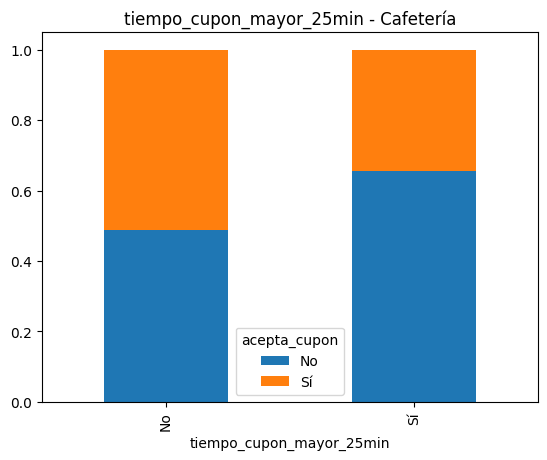

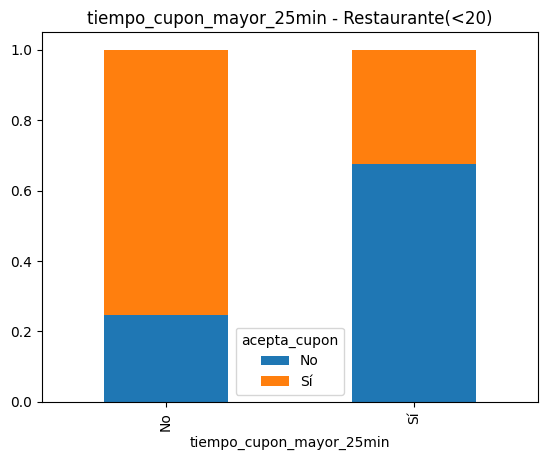

In [16]:
orden_frec = ['nunca', 'menos de 1', '1 a 3', '4 a 8', 'más de 8']

for col in ['frecuencia_bar', 'frecuencia_cafeteria', 'frecuencia_comida_para_llevar',
            'frecuencia_restaurante_menos_20', 'frecuencia_restaurante_20_a_50',
            'misma_direccion', 'tiempo_cupon_mayor_15min', 'tiempo_cupon_mayor_25min']:
    for nombre, s in [('Cafetería', cafe), ('Restaurante(<20)', rest)]:
        tabla = pd.crosstab(s[col], s['acepta_cupon'], normalize='index')
        if col.startswith('frecuencia'):
            tabla = tabla.reindex(orden_frec)
        tabla.plot(kind='bar', stacked=True, title=f'{col} - {nombre}')
        plt.show()

- Frecuencia de visita a cafeterias: es la variable de habitos más relacionada con el cupon de cafeteria, quienes nunca van aceptan solo el 19 %, frente a 65 a 69 % de quienes van al menos 1 a 3 veces al mes. Para eestaurante(<20) casi no hay diferencia entre 63 % y 77%.
- Frecuencia de visita a restaurantes (menos de 20 a mas de 20 y 50): en restaurante(<20) la aceptacion sube con la frecuencia de ir a restaurantes baratos, y en cafeteria tambien hay una subida suave con ambas variables.
- Frecuencia de bar y de comida para llevar: casi no cambian la aceptacion donde en cafeteria quedan entre 42 % y 52 %, por lo que no son relevantes.
- Distancia al lugar del cupón (`tiempo_cupon_mayor_25min`) es la variable con efecto mas fuerte del bloque ya que cuanod es asi la aceptacion cae a 35 % en cafeteria y a 33 % en Restaurante(<20). `tiempo_cupon_mayor_15min` muestra la misma tendencia pero mass suave.
- `misma_direccion`: tiene un efecto pequeño y en direcciones contrarias entre cupones.

## 2.7 Verificacion de consistencia y validez

Se listan las categorias de cada variable cualitativa para confirmar que coinciden con el diccionario de datos y que no hay una misma categoria escrita de dos formas, ademas se cruza `temperatura` con `clima` para ver si los valores son coherentes entre si.

In [17]:
cols_object = df_Base.select_dtypes(exclude='number').columns.drop('ocupacion')

for col in cols_object:
    print(f"--- Variable: {col} ---")
    print(df_Base[col].value_counts(dropna=False))
    print(f"Total de categorías distintas: {df_Base[col].nunique(dropna=False)}")
    print("-" * 40)

--- Variable: destino ---
destino
Sin lugar urgente    6270
Casa                 3233
Trabajo              3161
Name: count, dtype: int64
Total de categorías distintas: 3
----------------------------------------
--- Variable: acompanante ---
acompanante
Solo        7296
Amigo(s)    3291
Pareja      1072
Hijo(s)     1005
Name: count, dtype: int64
Total de categorías distintas: 4
----------------------------------------
--- Variable: clima ---
clima
Soleado     10052
Nevado       1404
Lluvioso     1208
Name: count, dtype: int64
Total de categorías distintas: 3
----------------------------------------
--- Variable: hora ---
hora
6:00 p.m.     3224
7:00 a.m.     3161
10:00 a.m.    2271
2:00 p.m.     2005
10:00 p.m.    2003
Name: count, dtype: int64
Total de categorías distintas: 5
----------------------------------------
--- Variable: cupon ---
cupon
Cafetería             3986
Restaurante(<20)      2776
Comida para llevar    2393
Bar                   2017
Restaurante(20-50)    1492
Name: 

In [18]:
print(df_Base.describe())

        temperatura
count  12664.000000
mean      63.287271
std       19.158130
min       30.000000
25%       55.000000
50%       80.000000
75%       80.000000
max       80.000000


In [19]:
pd.crosstab(df_Base['clima'], df_Base['temperatura'])

temperatura,30,55,80
clima,,,
Lluvioso,0,1208,0
Nevado,1404,0,0
Soleado,911,2628,6513


Al revisar el conteo de categorias de cada variable cualitativa se observa que todas tienen un numero de categorias coherente con el diccionario de datos y que no hay categorias escritas de dos formas distintas como mayusculas o minusculas mezcladas por lo que no es necesario normalizar el texto de las variables cualitativas. Se observan categorias con pocos registros como "Viudo(a)" en `estado_civil` y "Bachillerato incompleto" en `educacion` las cuales no se eliminan pero hay que tener presente que las conclusiones sobre ellas son menos confiables.

En cuanto a la validez, `temperatura` es la unica variable numerica y solo toma los valores 30, 55 y 80. El cruce con `clima` muestra que es coherente ya que con clima nevado solo aparece 30, con clima lluvioso solo 55 y con clima soleado aparecen los tres valores (30, 55 y 80).

## 2.8 Verificacion de variables redundantes

Se buscan variables constantes dentro de cada subconjunto y variables que repitan la misma informacion que otras.

In [20]:
for nombre, s in [('Cafetería', cafe), ('Restaurante(<20)', rest)]:
    print(nombre)
    print(s.nunique().sort_values().head(4), '\n')

Cafetería
cupon                      1
tiempo_cupon_mayor_5min    1
genero                     2
vigencia_cupon             2
dtype: int64 

Restaurante(<20)
cupon                      1
tiempo_cupon_mayor_5min    1
genero                     2
vigencia_cupon             2
dtype: int64 



In [21]:
pd.crosstab(df_Base['misma_direccion'], df_Base['direccion_opuesta'])

direccion_opuesta,No,Sí
misma_direccion,,
No,0,9944
Sí,2720,0


In [22]:
pd.crosstab([df_Base['tiempo_cupon_mayor_5min'], df_Base['tiempo_cupon_mayor_15min']],
            df_Base['tiempo_cupon_mayor_25min'])

tiempo_cupon_mayor_25min                            No    Sí
tiempo_cupon_mayor_5min tiempo_cupon_mayor_15min            
Sí                      No                        5551     0
                        Sí                        5602  1511

En ambos subconjuntos hay variables constantes: `cupon` solo tiene un valor que es el del propio subconjunto y `tiempo_cupon_mayor_5min` vale "Sí" en todos los registros por lo que no aportan información para predecir la aceptacion. Ademas, `misma_direccion` y `direccion_opuesta` son complementarias ya que cuando una es "Sí" la otra es "No" en todos los registros asi que basta con conservar una. Las variables `tiempo_cupon_mayor_5min`, `tiempo_cupon_mayor_15min` y `tiempo_cupon_mayor_25min` estan anidadas pero las de 15 y 25 minutos todavia distinguen entre lugares cercanos y lejanos por lo que se conservan.

# 3. Preparacion de los datos

Se plantea los problemas de calidad encontrados en la exploracion y las decisiones que se toman para corregirlos.

**3.1 Problemas identificados**

1. **Unicidad:** hay 7 filas duplicadas exactas en cada subconjunto (cerca del 0,2 %).
2. **Completitud:**
   - `vehiculo` tiene cerca del 99 % de valores nulos en ambos subconjuntos.
   - Las cinco variables `frecuencia_*` tienen entre 0,8 % y 1,8 % de valores nulos.
3. **Variables constantes o redundantes:**
   - `cupon` y `tiempo_cupon_mayor_5min` son constantes dentro de cada subconjunto.
   - `direccion_opuesta` es el complemento exacto de `misma_direccion`.
4. **Variables cualitativas con muchas categorías:** `ocupacion` tiene 25 categorías y varias variables (`hora`, `edad`, `educacion`, `ingreso`, `frecuencia_*`) tienen un orden natural.
5. **Desbalance de clases:** en Restaurante(<20), 70,7 % de los registros son "Sí" y 29,3 % "No"; Cafetería está balanceada (49,9 % y 50,1 %).

**3.2 Plan de procesamiento de datos**

1. **Duplicados:** eliminar las filas duplicadas exactas con `drop_duplicates()` antes de dividir en entrenamiento y prueba, para que un mismo registro no quede en ambos conjuntos.
2. **Variables a eliminar:** `vehiculo` (casi vacía), `cupon` y `tiempo_cupon_mayor_5min` (constantes) y `direccion_opuesta` (redundante con `misma_direccion`).
3. **Valores nulos:** imputar las variables `frecuencia_*` con la moda, dentro del Pipeline, calculada solo con el conjunto de entrenamiento.
4. **Codificación:**
   - Variables cualitativas (incluidas las que tienen orden natural): `OneHotEncoder`, para no imponer un orden numérico entre categorías.
   - `temperatura`: estandarización, útil para la regresión logística e inocua para árboles y bosques.
5. **Partición:** dividir cada subconjunto en 80 % entrenamiento y 20 % prueba de forma estratificada por `acepta_cupon`, con `random_state=42`.
6. **Desbalance (Restaurante(<20)):** se comparará el modelo sin balanceo con otro que use SMOTE, aplicado dentro de la validación cruzada (sección 7) para no filtrar información.

### 3.3 Implementacion

**3.3.1 Eliminacion de duplicados**

In [23]:
df_limpio = df_Base.drop_duplicates().copy()

print('Registros despues:', len(df_limpio))
print('Duplicados eliminados:', len(df_Base) - len(df_limpio))

Registros despues: 12590
Duplicados eliminados: 74


**3.3.2 Eliminacion de variables y separacion por cupon**

In [24]:
cols_eliminar = ['vehiculo', 'cupon', 'tiempo_cupon_mayor_5min', 'direccion_opuesta']

cafe_l = df_limpio[df_limpio['cupon'] == 'Cafetería'].drop(columns=cols_eliminar)
rest_l = df_limpio[df_limpio['cupon'] == 'Restaurante(<20)'].drop(columns=cols_eliminar)

print('Cafetería:', cafe_l.shape)
print('Restaurante(<20):', rest_l.shape)

Cafetería: (3979, 22)
Restaurante(<20): (2769, 22)


**3.3.3 Variable objetivo y particion en entrenamiento y prueba**

Para cada cupon se separan las caracteristicas (`X`) de la variable objetivo `acepta_cupon` (`y`) y se divide en 80 % entrenamiento y 20 % prueba. Se usa `stratify=y` para mantener la misma proporcion de clases en ambos conjuntos, algo importante en restaurante(<20) que esta desbalanceado y `random_state=42` para que el resultado sea reproducible.

In [25]:
X_cafe = cafe_l.drop(columns=['acepta_cupon'])
y_cafe = cafe_l['acepta_cupon']
X_cafe_train, X_cafe_test, y_cafe_train, y_cafe_test = train_test_split(
    X_cafe, y_cafe, test_size=0.2, random_state=42, stratify=y_cafe)

X_rest = rest_l.drop(columns=['acepta_cupon'])
y_rest = rest_l['acepta_cupon']
X_rest_train, X_rest_test, y_rest_train, y_rest_test = train_test_split(
    X_rest, y_rest, test_size=0.2, random_state=42, stratify=y_rest)

print('Cafetería  - train:', X_cafe_train.shape, '| test:', X_cafe_test.shape)
print('Restaurante(<20) - train:', X_rest_train.shape, '| test:', X_rest_test.shape)
print(y_rest_train.value_counts(normalize=True).round(3))
print(y_rest_test.value_counts(normalize=True).round(3))

Cafetería  - train: (3183, 21) | test: (796, 21)
Restaurante(<20) - train: (2215, 21) | test: (554, 21)
acepta_cupon
Sí    0.707
No    0.293
Name: proportion, dtype: float64
acepta_cupon
Sí    0.708
No    0.292
Name: proportion, dtype: float64


**3.3.4 Preprocesador**

Se define un `ColumnTransformer` con las transformaciones que se usaran en todos los modelos:

- **Variables cualitativas:** primero se imputan los valores nulos con la moda y luego se codifican con `OneHotEncoder`. Las variables con orden natural (`edad`, `educacion`, `ingreso`, `hora` y `frecuencia_*`) tambien se codifican con one-hot, para no imponer un orden numerico.
- **Variable numerica (`temperatura`):** se estandariza con `StandardScaler` que es necesario para la regresion logistica y no afecta a los arboles ni al bosque.

In [26]:
categorical_features = X_cafe_train.select_dtypes(exclude='number').columns
numerical_features = X_cafe_train.select_dtypes(include='number').columns

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='if_binary'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('numerical', StandardScaler(), numerical_features),
        ('categorical', categorical_transformer, categorical_features)
    ]
)

print('Variables numéricas:', list(numerical_features))
print('Variables cualitativas:', len(categorical_features))

Variables numéricas: ['temperatura']
Variables cualitativas: 20


# 4. Regresión logística

En esta sección se construye un modelo de regresión logística para cada tipo de cupón (Cafetería y Restaurante(<20)). Cada modelo se arma como un `Pipeline` que une el preprocesador definido en 3.3.4 con el clasificador, de modo que las transformaciones (imputación, one-hot, estandarización) se ajusten solo con los datos de entrenamiento de cada partición de la validación cruzada. Así se evita la fuga de información.

**Búsqueda de hiperparámetros.** Se usa `GridSearchCV` con validación cruzada estratificada de 5 particiones (`StratifiedKFold`). La estratificación mantiene en cada partición la proporción de clases del conjunto original, algo clave en Restaurante(<20), que está desbalanceado (70,7 % "Sí" y 29,3 % "No"). Se exploran:
- **Regularización (`penalty`):** L1 y L2.
- **Solver:** `newton-cg`, `lbfgs` y `liblinear` para L2, y solo `liblinear` para L1, que es el único de estos tres que soporta L1. Se descartó `elasticnet` porque no se vio en el curso.
- **`C`:** inverso de la fuerza de regularización. Valores entre 0.1 y 1, es decir, regularización moderada.

**Métrica de selección: `F1 macro`** Es el promedio del F1 de ambas clases. En Restaurante(<20) la `accuracy` engaña porque predecir siempre "Sí" daría 70,7 %. El F1 macro obliga a que el modelo también acierte con la clase minoritaria ("No").

En primer lugar, se decide crear una función `entrenar_y_evaluar`, la cual se va a reutilizar en cada uno de los modelos que se construya en este laboratorio como una forma de mantener consistencia y ahorrar código a lo largo del presente. Además, se crearán con las estructuras `resltados` y `modelos`, las cuales usaremos eventualmente para construir la tabla comparativa para determinar el mejor de los modelos construidos. 

In [27]:
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

resultados = []   # acumula métricas de todos los modelos (se usará en la tabla comparativa)
modelos = {}      # guarda los GridSearchCV entrenados

def entrenar_y_evaluar(cupon, nombre_modelo, pipeline, param_grid, datos):
    Xtr, Xte, ytr, yte = datos
    gs = GridSearchCV(pipeline, param_grid, cv=cv, scoring='f1_macro',
                      n_jobs=-1, return_train_score=True)
    gs.fit(Xtr, ytr)
    modelos[(cupon, nombre_modelo)] = gs

    # Resumen de la búsqueda
    print(f'=== {nombre_modelo} - {cupon} ===')
    print('Mejores hiperparámetros:', gs.best_params_)
    print(f'F1 macro en validación cruzada: {gs.best_score_:.3f}')
    print(f'F1 macro en entrenamiento:      {gs.cv_results_["mean_train_score"][gs.best_index_]:.3f}\n')

    cols = ['params', 'mean_test_score', 'std_test_score', 'rank_test_score']
    display(pd.DataFrame(gs.cv_results_)[cols].sort_values('rank_test_score').head(5))

    # Evaluación sobre el conjunto de prueba
    y_pred = gs.predict(Xte)
    print(classification_report(yte, y_pred, digits=3))
    ConfusionMatrixDisplay.from_predictions(yte, y_pred, cmap='Blues')
    plt.title(f'{nombre_modelo} - {cupon}')
    plt.show()

    # Guardar métricas para la tabla comparativa
    rep = classification_report(yte, y_pred, output_dict=True)
    resultados[:] = [r for r in resultados if not (r['Cupón'] == cupon and r['Modelo'] == nombre_modelo)]
    resultados.append({
        'Cupón': cupon, 'Modelo': nombre_modelo,
        'Precisión (Sí)': rep['Sí']['precision'], 'Recall (Sí)': rep['Sí']['recall'], 'F1 (Sí)': rep['Sí']['f1-score'],
        'Precisión (No)': rep['No']['precision'], 'Recall (No)': rep['No']['recall'], 'F1 (No)': rep['No']['f1-score'],
        'F1 macro': rep['macro avg']['f1-score'],
    })
    return gs

## 4.1 Definición del pipeline y la grilla

El pipeline tiene dos pasos: `preprocesador` (el `ColumnTransformer` de 3.3.4) y `modelo` (la regresión logística). Los nombres de los pasos son los que se usan como prefijo en la grilla (`modelo__C`, etc.). Se aumenta `max_iter` para asegurar la convergencia de los solvers iterativos.

La grilla se escribe como una lista de diccionarios porque no todas las combinaciones son válidas: L1 solo funciona con `liblinear`. En total son 20 combinaciones × 5 particiones = 100 entrenamientos por cupón.

In [28]:
pipe_lr = Pipeline([
    ('preprocesador', preprocessor),
    ('modelo', LogisticRegression(max_iter=5000, random_state=42))
])

Recordemos que el proceso para encontrar el mejor set de hiperparámteros es iterativos, por lo que en cada modelo podemos llegar a ver diferentes versiones de `param_grid` hasta que encontramos la combinación con mejor desempeño.

In [29]:
# Primera versión del grid de hiperparámetros para Logistic Regression
# param_grid_lr = [
#     # Combinaciones válidas con L2
#     {'modelo__penalty': ['l2'],
#      'modelo__solver': ['newton-cg', 'lbfgs', 'liblinear'],
#      'modelo__C': [0.1, 0.2, 0.5, 0.8, 1]},
#     # Combinaciones válidas con L1
#     {'modelo__penalty': ['l1'],
#      'modelo__solver': ['liblinear'],
#      'modelo__C': [0.1, 0.2, 0.5, 0.8, 1]},
# ]

# Segunda versión del grid de hiperparámetros para Logistic Regression.
# En la iteración pasada se encontró que el mejor modelo para los cupones de cafetería era L1 con solver liblinear y C = 0.2, 
# por lo que se reduce el grid a esa combinación y se exploran valores de C más cercanos a 0.2.
# También se encontró que el mejor modelo para los cupones de restaurante era L1 con solver liblinear y C = 0.2,
# así que se añaden valores de C más cercanos a 0.2 para explorar si se puede mejorar el desempeño.
param_grid_lr = [
    
    {'modelo__penalty': ['l2'],
     'modelo__solver': ['newton-cg', 'lbfgs', 'liblinear'],
     'modelo__C': [0.1, 0.2, 0.5, 0.8, 1]},
    
    {'modelo__penalty': ['l1'],
     'modelo__solver': ['liblinear'],
     'modelo__C': [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5]},
]

Habiendo reducido y probado el rango para C = [0.2, 0.5] se encontró que el mejor modelo para los **cupones de  cafetería** era L1 con solver liblinear y C = 0.4
Decidimos tomar ese modelo como el mejor y no seguir explorando valores de C más cercanos a 0.4, ya que se encontró que el desempeño del modelo no mejora significativamente al hacerlo.

Por su lado, para los **cupones de restaurante (<20)** se determinó que el modelo modelo es L1 con solver liblinear y C = 0.2 desde la primera iteración y se mantuvo igual al considerar otros valores cercanos.

## 4.2 Regresión logística - Cafetería

Se entrena la búsqueda con el 80 % de entrenamiento de Cafetería y se evalúa el mejor modelo sobre el 20 % de prueba. Además del reporte de clasificación, se muestra la matriz de confusión: las filas son la clase real y las columnas la predicha, así se ve qué tipo de errores comete el modelo y no solo cuántos.

=== Regresión logística - Cafetería ===
Mejores hiperparámetros: {'modelo__C': 0.4, 'modelo__penalty': 'l1', 'modelo__solver': 'liblinear'}
F1 macro en validación cruzada: 0.721
F1 macro en entrenamiento:      0.735



c:\Users\Administrador\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\Administrador\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


,params,mean_test_score,std_test_score,rank_test_score
21,"{'modelo__C': 0.4, 'modelo__penalty': 'l1', 'm...",0.720948,0.013335,1
20,"{'modelo__C': 0.35, 'modelo__penalty': 'l1', '...",0.720303,0.012309,2
22,"{'modelo__C': 0.45, 'modelo__penalty': 'l1', '...",0.720007,0.013702,3
19,"{'modelo__C': 0.3, 'modelo__penalty': 'l1', 'm...",0.718722,0.012678,4
17,"{'modelo__C': 0.2, 'modelo__penalty': 'l1', 'm...",0.718415,0.011327,5


              precision    recall  f1-score   support

          No      0.712     0.689     0.701       399
          Sí      0.698     0.720     0.709       397

    accuracy                          0.705       796
   macro avg      0.705     0.705     0.705       796
weighted avg      0.705     0.705     0.705       796



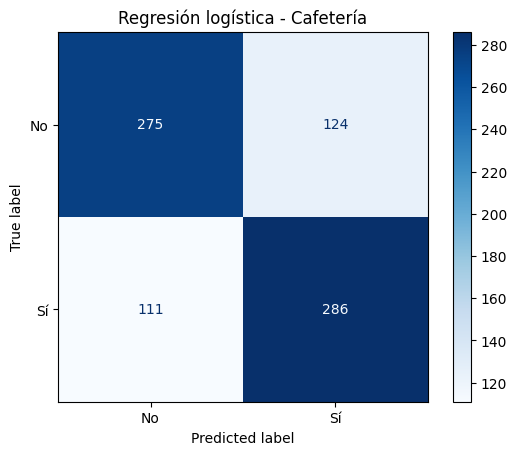

In [30]:
gs_lr_cafe = entrenar_y_evaluar('Cafetería', 'Regresión logística', pipe_lr, param_grid_lr,
                                (X_cafe_train, X_cafe_test, y_cafe_train, y_cafe_test))

**Análisis - Cafetería.**
- **Hiperparámetros:** la mejor combinación fue L1 con `liblinear` y `C = 0.4`. Sin embargo, la diferencia con las demás es mínima: el F1 macro en validación cruzada es 0.721 con L1 y entre 0.716 y 0.717 con L2, sin importar el solver. Los tres solvers con L2 convergen prácticamente a la misma solución, como es esperable porque optimizan el mismo problema. En este caso la regularización no es decisiva.
- **Sobreajuste:** el F1 macro en entrenamiento (0.735) es solo ligeramente mayor que en validación (0.721), lo que indica que no hay sobreajuste. El modelo es simple y la regularización moderada es suficiente.
- **Prueba:** el desempeño es parejo entre clases, con F1 de 0.71 para "Sí" y 0.70 para "No" y una exactitud de 0.705. Esto es coherente con que Cafetería está balanceada. En la matriz de confusión, 286 "Sí" y 275 "No" se clasifican bien, y los errores se reparten de forma similar (124 "No" predichos como "Sí" y 111 "Sí" predichos como "No").
- **Conclusión:** el modelo acierta cerca de 7 de cada 10 veces. Es una línea base razonable, pero no excelente, lo que sugiere que parte de la decisión de aceptar un cupón depende de factores no capturados por un modelo lineal o por las variables disponibles.

## 4.3 Regresión logística - Restaurante(<20)

Se repite el procedimiento con el subconjunto de Restaurante(<20). Aquí hay que mirar con especial atención el **recall de la clase "No"**: la minoritaria y la que cuesta más detectar. La exactitud por sí sola no sirve porque predecir siempre "Sí" ya da 70,7 %.

=== Regresión logística - Restaurante(<20) ===
Mejores hiperparámetros: {'modelo__C': 0.2, 'modelo__penalty': 'l1', 'modelo__solver': 'liblinear'}
F1 macro en validación cruzada: 0.674
F1 macro en entrenamiento:      0.676



c:\Users\Administrador\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\Administrador\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


,params,mean_test_score,std_test_score,rank_test_score
17,"{'modelo__C': 0.2, 'modelo__penalty': 'l1', 'm...",0.674088,0.008754,1
18,"{'modelo__C': 0.25, 'modelo__penalty': 'l1', '...",0.672874,0.009716,2
19,"{'modelo__C': 0.3, 'modelo__penalty': 'l1', 'm...",0.671612,0.010108,3
3,"{'modelo__C': 0.2, 'modelo__penalty': 'l2', 'm...",0.671546,0.014245,4
5,"{'modelo__C': 0.2, 'modelo__penalty': 'l2', 'm...",0.671546,0.014245,4


              precision    recall  f1-score   support

          No      0.677     0.401     0.504       162
          Sí      0.788     0.921     0.849       392

    accuracy                          0.769       554
   macro avg      0.733     0.661     0.677       554
weighted avg      0.756     0.769     0.748       554



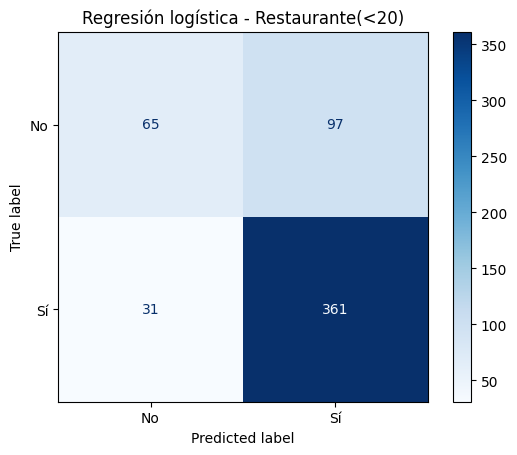

In [31]:
gs_lr_rest = entrenar_y_evaluar('Restaurante(<20)', 'Regresión logística', pipe_lr, param_grid_lr,
                                (X_rest_train, X_rest_test, y_rest_train, y_rest_test))

**Análisis - Restaurante(<20).**
- **Hiperparámetros:** de nuevo la mejor combinación fue L1 con `liblinear` y `C = 0.2` (F1 macro en validación 0.674), con diferencias muy pequeñas frente a L2 (0.672). Los solvers de L2 vuelven a ser equivalentes entre sí.
- **Sobreajuste:** el F1 macro en entrenamiento (0.676) es casi igual al de validación (0.674), así que el modelo no sobreajusta, pero tampoco logra ajustar bien los datos, es decir, tiene sesgo alto.
- **El desbalance sí afecta:** en prueba el modelo tiene exactitud de 0.769, pero esa cifra engaña. La clase "Sí" tiene F1 de 0.85 (recall 0.92), mientras que la clase "No" tiene F1 de solo 0.50 y un **recall de 0.40**. La matriz de confusión lo muestra: de 162 conductores que realmente rechazan el cupón, el modelo solo identifica 65 y deja pasar 97 como si lo fueran a aceptar.
- **Diferencia con Cafetería:** aquí el modelo tiende a predecir "Sí", la clase mayoritaria, porque esa decisión minimiza el error global. El F1 macro (0.677) es menor que el de Cafetería (0.705) a pesar de que la exactitud parece mayor (0.769 contra 0.705), lo que confirma que la exactitud es una métrica engañosa en este subconjunto.

# 5. Árboles de decisión

Se construye un árbol de decisión para cada tipo de cupón, con la misma estructura de la sección anterior: `Pipeline` (preprocesador + modelo), `GridSearchCV` con `StratifiedKFold` de 5 particiones y F1 macro como métrica de selección.

**Hiperparámetros explorados**
- **`max_depth`**: controla cuántas preguntas en cadena puede hacer el árbol. Es el principal control contra el sobreajuste.
- **`min_samples_leaf`**: mínimo de registros por hoja. Valores altos evitan hojas que memorizan casos individuales.
- **`criterion`** (`gini`, `entropy`): medida de impureza para elegir cada división.

A diferencia de la regresión logística, un árbol sin restricciones puede ajustarse perfectamente a los datos de entrenamiento. Por eso, además de la matriz de confusión, se grafica el árbol resultante y se compara el desempeño en entrenamiento y validación.

In [32]:
def graficar_arbol(gs, cupon, profundidad_grafica=3):
    """Dibuja los primeros niveles del árbol del mejor modelo encontrado."""
    mejor = gs.best_estimator_
    arbol = mejor.named_steps['modelo']
    nombres = mejor.named_steps['preprocesador'].get_feature_names_out()
    print(f'Profundidad real del árbol: {arbol.get_depth()} | Hojas: {arbol.get_n_leaves()}')
    plt.figure(figsize=(24, 10))
    plot_tree(arbol, feature_names=nombres, class_names=list(arbol.classes_),
              filled=True, impurity=False, proportion=True,
              max_depth=profundidad_grafica, fontsize=9)
    plt.title(f'Árbol de decisión - {cupon} (primeros {profundidad_grafica} niveles)')
    plt.show()

def ver_sobreajuste(gs):
    """Compara entrenamiento vs. validación para el árbol sin restricciones."""
    r = pd.DataFrame(gs.cv_results_)
    sin_limite = r[(r['param_modelo__max_depth'].isna()) & (r['param_modelo__min_samples_leaf'] == 1)]
    display(sin_limite[['param_modelo__criterion', 'mean_train_score', 'mean_test_score']].round(3))

## 5.1 Definición del pipeline y la grilla

El pipeline, tal y como el de la regresión logística, reutiliza el `preprocesador` (sección 3.3.4). Por su parte, la grilla sí específica para los modelos de árbol de decisión y los hiperparámetros especificados. 

In [33]:
pipe_dt = Pipeline([
    ('preprocesador', preprocessor),
    ('modelo', DecisionTreeClassifier(random_state=42))
])

In [34]:
# Primera y única iteración del grid de hiperparámetros para Decision Tree
param_grid_dt = {
    'modelo__max_depth': [3, 5, 7, 10, None],
    'modelo__min_samples_leaf': [1, 5, 10, 20, 50, 100],
    'modelo__criterion': ['gini', 'entropy'],
}

En esta caso se decide que la primera versión del grid de hiperparámetros será también la inicial, pues intentos de modificaciones no mostraron una mejoría significativa.

## 5.2 Árbol de decisión - Cafetería

Se entrena la búsqueda y se evalúa el mejor árbol en el conjunto de prueba. Después se grafican sus primeros tres niveles (el árbol completo es demasiado grande para leerse). En cada nodo se muestra la condición de división, el porcentaje de registros que llegan a él, la proporción de cada clase (`value = [No, Sí]`) y la clase mayoritaria. Como las variables están codificadas con one-hot, una condición como `frecuencia_cafeteria_nunca <= 0.5` equivale a preguntar "¿el conductor visita cafeterías, aunque sea de vez en cuando?": la rama *True* es "sí visita" y la *False* es "nunca va".

=== Árbol de decisión - Cafetería ===
Mejores hiperparámetros: {'modelo__criterion': 'gini', 'modelo__max_depth': 7, 'modelo__min_samples_leaf': 50}
F1 macro en validación cruzada: 0.715
F1 macro en entrenamiento:      0.727



,params,mean_test_score,std_test_score,rank_test_score
16,"{'modelo__criterion': 'gini', 'modelo__max_dep...",0.714970,0.013486,1
46,"{'modelo__criterion': 'entropy', 'modelo__max_...",0.714970,0.013486,1
52,"{'modelo__criterion': 'entropy', 'modelo__max_...",0.714138,0.013554,3
58,"{'modelo__criterion': 'entropy', 'modelo__max_...",0.714138,0.013554,3
28,"{'modelo__criterion': 'gini', 'modelo__max_dep...",0.713933,0.013528,5


              precision    recall  f1-score   support

          No      0.699     0.652     0.674       399
          Sí      0.672     0.718     0.694       397

    accuracy                          0.685       796
   macro avg      0.686     0.685     0.684       796
weighted avg      0.686     0.685     0.684       796



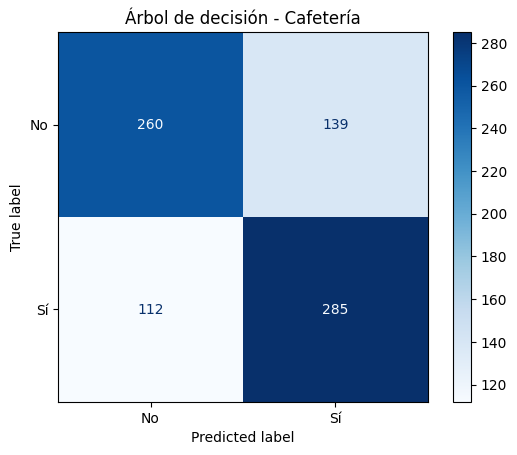

In [35]:
gs_dt_cafe = entrenar_y_evaluar('Cafetería', 'Árbol de decisión', pipe_dt, param_grid_dt,
                                (X_cafe_train, X_cafe_test, y_cafe_train, y_cafe_test))

Profundidad real del árbol: 7 | Hojas: 41


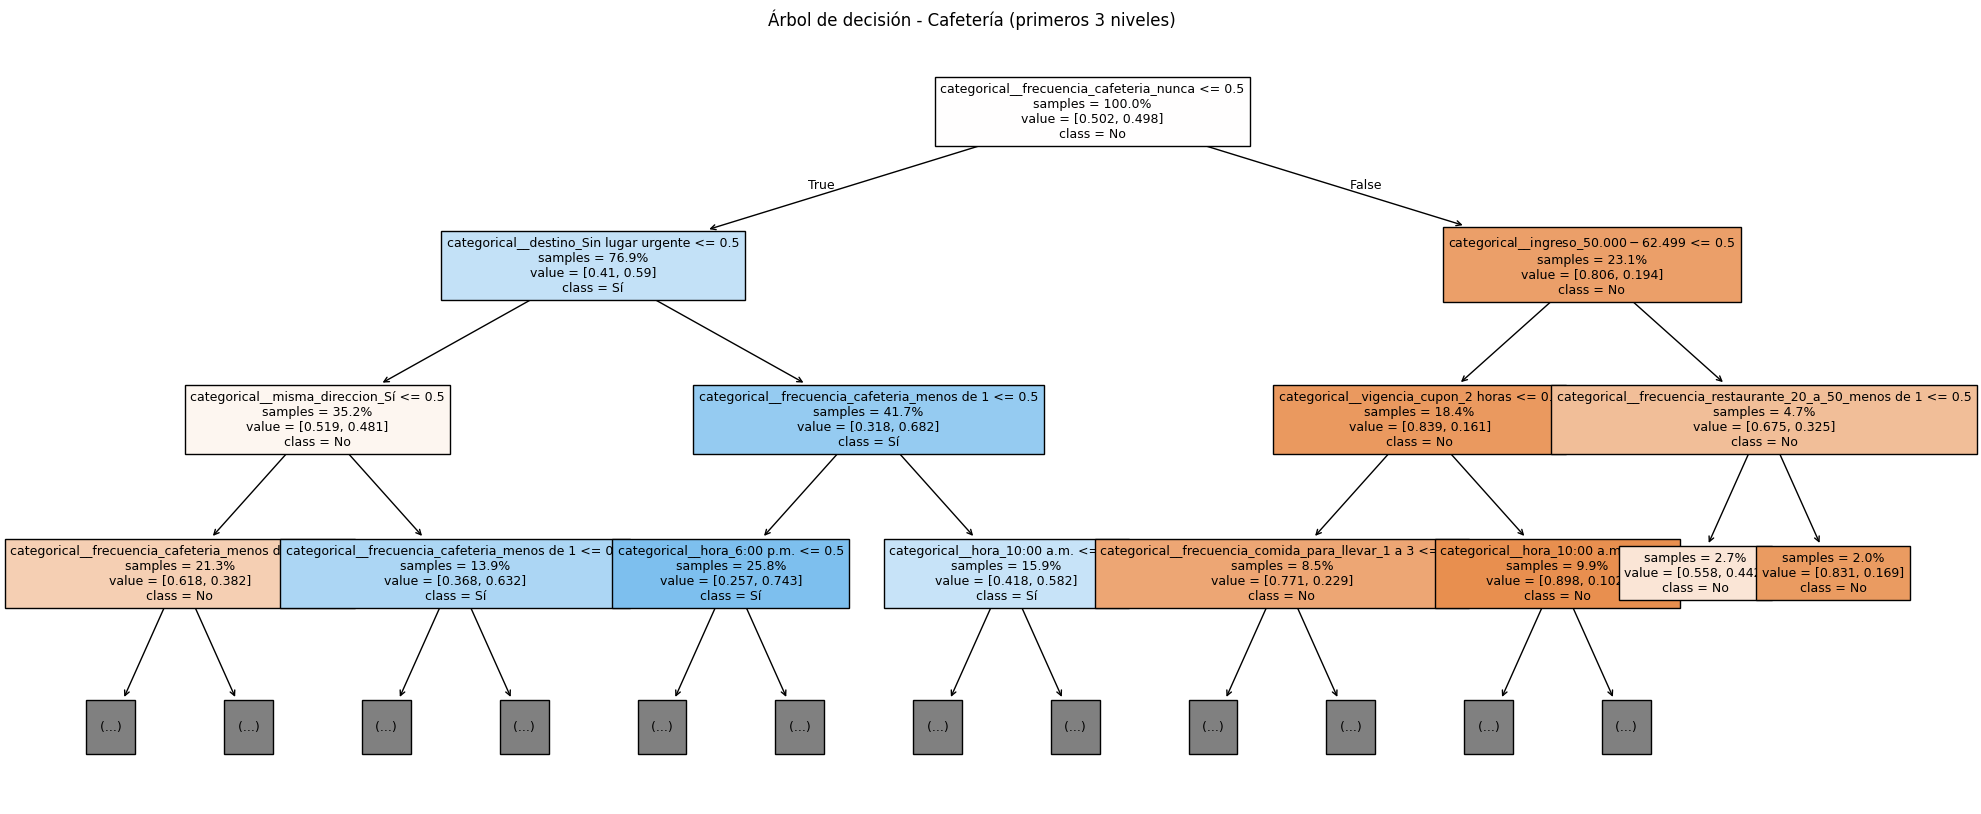

,param_modelo__criterion,mean_train_score,mean_test_score
24,gini,0.999,0.678
54,entropy,0.999,0.677


In [36]:
graficar_arbol(gs_dt_cafe, 'Cafetería')
ver_sobreajuste(gs_dt_cafe)

**Análisis - Cafetería.**
- **Hiperparámetros:** el mejor árbol usa `max_depth = 7` y `min_samples_leaf = 50`, con F1 macro de 0.715 en validación cruzada. El criterio (`gini` o `entropy`) no importa: ambos obtienen exactamente el mismo puntaje. Varias configuraciones quedan casi empatadas porque con hojas de al menos 50 registros el árbol rara vez necesita más de 7 niveles.
- **Sobreajuste:** el árbol sin restricciones (`max_depth=None`, `min_samples_leaf=1`) obtiene cerca de 0.999 en entrenamiento pero solo ≈ 0.68 en validación: memoriza los datos. Al exigir hojas grandes, la brecha casi desaparece (0.727 contra 0.715). Con `max_depth = 3` el árbol, en cambio, queda corto (0.672), así que existe un punto medio. Esto ilustra el equilibrio entre sesgo y varianza.
- **Prueba:** exactitud de 0.685 y F1 macro de 0.684. Los errores son parejos entre clases (139 "No" clasificados como "Sí" y 112 "Sí" como "No"). El rendimiento es **ligeramente inferior** al de la regresión logística (0.705), es decir, la relación entre las variables y la aceptación es en buena parte aditiva. Además, el árbol individual rinde algo menos que el modelo lineal por su alta varianza; la sección de Random Forest muestra que sí hay relaciones no lineales que puede aprovechar un árbol de decisión.
- **Lectura del árbol:** la primera división es `frecuencia_cafeteria_nunca`. Los conductores que nunca van a cafeterías (23 % de los registros) rechazan el cupón en aproximadamente 81 % de los casos. Entre quienes sí van, el árbol pregunta si el destino es "Sin lugar urgente", y los que tienen tiempo libre aceptan más. También aparecen la dirección del lugar (`misma_direccion`), la hora y la vigencia del cupón. Es una explicación intuitiva: aceptan más quienes ya consumen café y no tienen prisa.

## 5.3 Árbol de decisión - Restaurante(<20)

Se repite el procedimiento con Restaurante(<20). Como antes, el foco está en el recall de la clase minoritaria ("No").

=== Árbol de decisión - Restaurante(<20) ===
Mejores hiperparámetros: {'modelo__criterion': 'entropy', 'modelo__max_depth': 7, 'modelo__min_samples_leaf': 50}
F1 macro en validación cruzada: 0.674
F1 macro en entrenamiento:      0.680



,params,mean_test_score,std_test_score,rank_test_score
52,"{'modelo__criterion': 'entropy', 'modelo__max_...",0.673607,0.014184,1
58,"{'modelo__criterion': 'entropy', 'modelo__max_...",0.673607,0.014184,1
46,"{'modelo__criterion': 'entropy', 'modelo__max_...",0.673607,0.014184,1
43,"{'modelo__criterion': 'entropy', 'modelo__max_...",0.673400,0.014857,4
22,"{'modelo__criterion': 'gini', 'modelo__max_dep...",0.669898,0.018269,5


              precision    recall  f1-score   support

          No      0.604     0.414     0.491       162
          Sí      0.786     0.888     0.834       392

    accuracy                          0.749       554
   macro avg      0.695     0.651     0.662       554
weighted avg      0.732     0.749     0.733       554



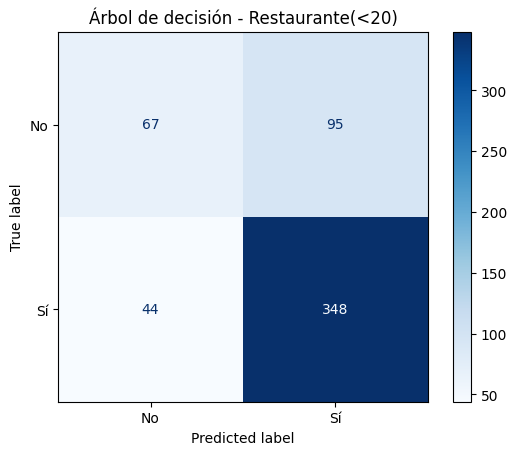

In [37]:
gs_dt_rest = entrenar_y_evaluar('Restaurante(<20)', 'Árbol de decisión', pipe_dt, param_grid_dt,
                                (X_rest_train, X_rest_test, y_rest_train, y_rest_test))

Profundidad real del árbol: 7 | Hojas: 26


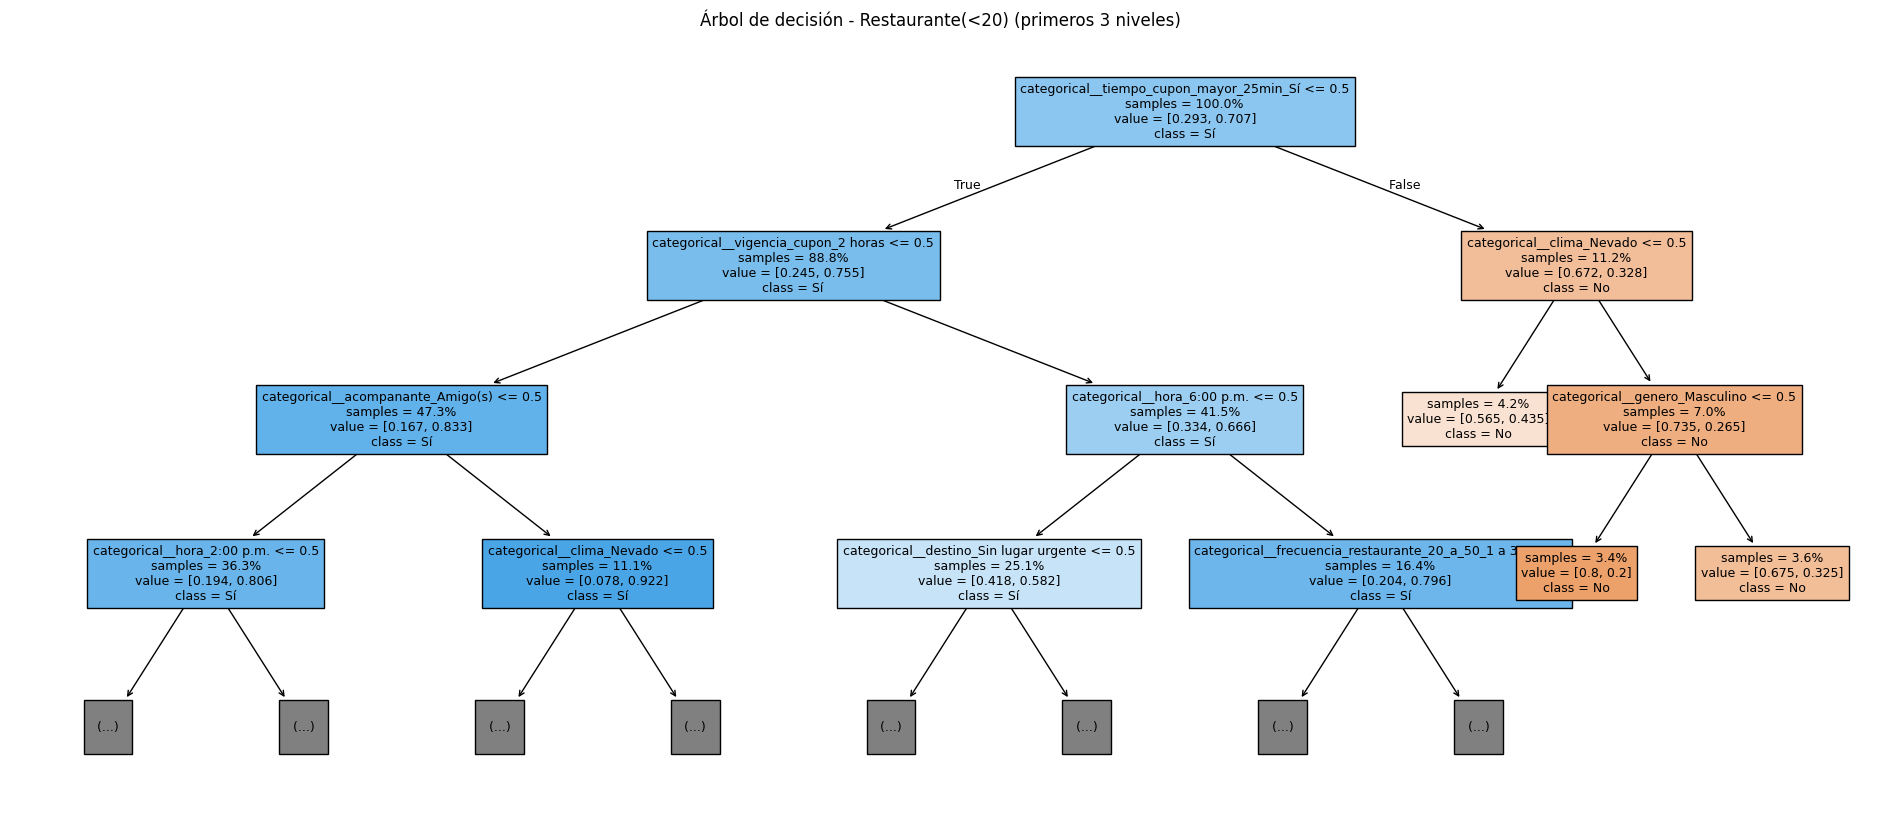

,param_modelo__criterion,mean_train_score,mean_test_score
24,gini,0.999,0.620
54,entropy,0.999,0.647


In [38]:
graficar_arbol(gs_dt_rest, 'Restaurante(<20)')
ver_sobreajuste(gs_dt_rest)

**Análisis - Restaurante(<20).**
- **Hiperparámetros:** el mejor árbol usa `criterion = entropy`, `min_samples_leaf = 50` y `max_depth = 7` (F1 macro en validación 0.674). Las configuraciones con profundidad 7, 10 y sin límite dan exactamente el mismo puntaje porque el árbol, con hojas de mínimo 50 registros, nunca supera la profundidad 7; `GridSearchCV` se queda con la primera. Aquí `entropy` supera levemente a `gini` (0.674 contra 0.670).
- **Sobreajuste:** igual que en Cafetería, el árbol sin restricciones memoriza el entrenamiento (≈ 0.999) y cae a 0.62-0.65 en validación. El árbol seleccionado casi no tiene brecha (0.680 contra 0.674), pero con solo 26 hojas.
- **Prueba:** la exactitud es de 0.749, pero el **recall de "No" es 0.414** (precisión 0.604, F1 0.491): de 162 rechazos reales, el árbol detecta 67 y deja pasar 95. Es prácticamente igual al de la regresión logística (0.401), y el F1 macro es un poco menor (0.662 contra 0.677). Cambiar de modelo lineal a árbol no resuelve el problema de la clase minoritaria, lo que apunta al desbalance como causa principal.
- **Lectura del árbol:** la primera división es `tiempo_cupon_mayor_25min`. Cuando el establecimiento queda a más de 25 minutos (11 % de los registros), el rechazo sube a 67 %. Luego aparecen la vigencia del cupón (2 horas), la hora (6:00 p.m.) y el clima nevado. A diferencia de Cafetería, aquí pesan más las variables de **contexto y logística** que los hábitos de consumo: la decisión de aceptar depende de qué tan cómodo es llegar al sitio más que del perfil del conductor. Esto se retomará en el análisis de variables relevantes.

# 6. Random Forest

Un Random Forest entrena muchos árboles de decisión, cada uno con una muestra aleatoria (con reemplazo) de los registros y considerando solo un subconjunto aleatorio de variables en cada división. La predicción final se obtiene por votación. Al promediar árboles distintos, se reduce la varianza que tiene un árbol individual (visible en la sección anterior, donde un árbol sin restricciones memorizaba el entrenamiento).

Se mantiene la misma estructura: `Pipeline`, `StratifiedKFold` de 5 particiones y F1 macro como métrica de selección.

**Hiperparámetros explorados**
- **`n_estimators`**: número de árboles. Más árboles estabilizan el resultado, pero con rendimientos decrecientes y mayor costo computacional.
- **`max_depth`**: profundidad máxima de cada árbol.
- **`min_samples_leaf`**: mínimo de registros por hoja.

Se usan menos valores que en el árbol individual porque entrenar un bosque es mucho más costoso (cada combinación entrena cientos de árboles por cada una de las 5 particiones).

In [39]:
pipe_rf = Pipeline([
    ('preprocesador', preprocessor),
    ('modelo', RandomForestClassifier(random_state=42))
])

param_grid_rf = {
    'modelo__n_estimators': [100, 200],
    'modelo__max_depth': [5, 10, None],
    'modelo__min_samples_leaf': [1, 5, 20],
}

## 6.1 Random Forest - Cafetería

Se entrena la búsqueda y se evalúa el mejor bosque en el conjunto de prueba. A diferencia de un árbol único, un bosque no se puede dibujar de forma legible (son cientos de árboles), por eso aquí solo se muestran la matriz de confusión y el reporte de clasificación. La interpretación de las variables más influyentes se hace de forma conjunta en la sección de importancia de variables.

=== Random Forest - Cafetería ===
Mejores hiperparámetros: {'modelo__max_depth': None, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 100}
F1 macro en validación cruzada: 0.757
F1 macro en entrenamiento:      0.999



,params,mean_test_score,std_test_score,rank_test_score
12,"{'modelo__max_depth': None, 'modelo__min_sampl...",0.756680,0.006193,1
13,"{'modelo__max_depth': None, 'modelo__min_sampl...",0.756029,0.003977,2
7,"{'modelo__max_depth': 10, 'modelo__min_samples...",0.743407,0.010601,3
6,"{'modelo__max_depth': 10, 'modelo__min_samples...",0.740563,0.016371,4
15,"{'modelo__max_depth': None, 'modelo__min_sampl...",0.736597,0.018024,5


              precision    recall  f1-score   support

          No      0.791     0.769     0.780       399
          Sí      0.775     0.796     0.785       397

    accuracy                          0.783       796
   macro avg      0.783     0.783     0.783       796
weighted avg      0.783     0.783     0.783       796



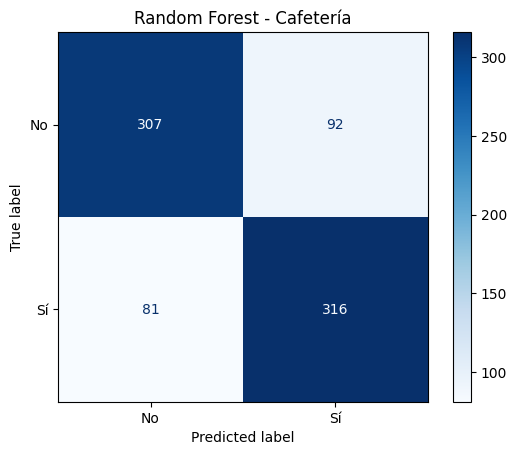

In [40]:
gs_rf_cafe = entrenar_y_evaluar('Cafetería', 'Random Forest', pipe_rf, param_grid_rf,
                                (X_cafe_train, X_cafe_test, y_cafe_train, y_cafe_test))

**Análisis - Cafetería.**
- **Hiperparámetros:** el mejor bosque no tiene restricciones de profundidad (`max_depth = None`) ni de tamaño de hoja (`min_samples_leaf = 1`), con F1 macro de 0.757 en validación cruzada. Restringir más los árboles empeora el resultado de forma consistente: con `min_samples_leaf = 5` baja a 0.737, con 20 a 0.722, y con `max_depth = 5` a 0.716. A diferencia de un árbol individual, en un bosque conviene que cada árbol sea flexible, porque el promedio entre árboles ya controla el sobreajuste. Pasar de 100 a 200 árboles prácticamente no cambia el resultado (0.757 contra 0.756).
- **Brecha entre entrenamiento y validación:** el F1 en entrenamiento es de 0.999, frente a 0.757 en validación. Esta diferencia no es un error: cada árbol individual memoriza su muestra de entrenamiento, y por eso el resultado en entrenamiento es engañoso. Lo que importa es la estimación de validación y, sobre todo, la de prueba.
- **Prueba:** exactitud de 0.783 y F1 macro de 0.783, con errores parejos entre clases (92 "No" clasificados como "Sí" y 81 "Sí" como "No"). Es la mejora más clara hasta ahora: supera a la regresión logística (0.707) y al árbol de decisión (0.684) en unos 8 y 10 puntos respectivamente.
- **Conclusión:** que un conjunto de árboles supere por tanto a un modelo lineal indica que la aceptación del cupón depende de **combinaciones de factores** (interacciones y relaciones no lineales entre variables) que la regresión logística no puede representar.

## 6.2 Random Forest - Restaurante(<20)

Se repite el procedimiento con Restaurante(<20), prestando atención al recall de la clase "No".

=== Random Forest - Restaurante(<20) ===
Mejores hiperparámetros: {'modelo__max_depth': None, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 200}
F1 macro en validación cruzada: 0.700
F1 macro en entrenamiento:      0.999



,params,mean_test_score,std_test_score,rank_test_score
13,"{'modelo__max_depth': None, 'modelo__min_sampl...",0.699880,0.006090,1
12,"{'modelo__max_depth': None, 'modelo__min_sampl...",0.697347,0.005326,2
6,"{'modelo__max_depth': 10, 'modelo__min_samples...",0.672976,0.014148,3
7,"{'modelo__max_depth': 10, 'modelo__min_samples...",0.667866,0.011631,4
15,"{'modelo__max_depth': None, 'modelo__min_sampl...",0.661555,0.017097,5


              precision    recall  f1-score   support

          No      0.680     0.420     0.519       162
          Sí      0.793     0.918     0.851       392

    accuracy                          0.773       554
   macro avg      0.736     0.669     0.685       554
weighted avg      0.760     0.773     0.754       554



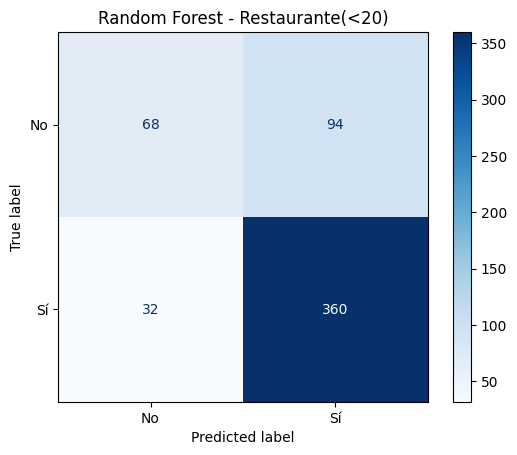

In [41]:
gs_rf_rest = entrenar_y_evaluar('Restaurante(<20)', 'Random Forest', pipe_rf, param_grid_rf,
                                (X_rest_train, X_rest_test, y_rest_train, y_rest_test))

**Análisis - Restaurante(<20).**
- **Hiperparámetros:** de nuevo la mejor configuración es la menos restringida (`max_depth = None`, `min_samples_leaf = 1`), ahora con 200 árboles y F1 macro de 0.700 en validación. La tendencia es la misma que en Cafetería: más restricción implica peor resultado (0.662 con `min_samples_leaf = 5` y 0.631 con 20). La diferencia entre 100 y 200 árboles es pequeña (0.697 contra 0.700).
- **Mejora en validación:** el bosque (0.700) supera al árbol (0.674) y a la regresión logística (0.674) en validación cruzada, pero la mejora es menor que en Cafetería.
- **Prueba:** exactitud de 0.773 y F1 macro de 0.685. El **recall de "No" es 0.420** (precisión 0.680, F1 0.519): de 162 rechazos reales, el bosque detecta 68 y deja pasar 94. Frente a la regresión logística (recall 0.401, F1 macro 0.677) y al árbol (0.414 y 0.662), la mejora en el conjunto de prueba es de menos de un punto en F1 macro, una diferencia que con 554 registros está dentro del ruido.
- **Diferencia entre cupones:** el bosque pasa de 0.707 a 0.783 en Cafetería, pero de 0.677 a 0.685 en Restaurante(<20). Que un modelo mucho más flexible casi no mejore donde la clase "No" es minoritaria sugiere que el obstáculo principal no es la capacidad del modelo, sino el desbalance (y posiblemente que las variables disponibles explican menos la decisión en este cupón). Esto motiva probar balanceo de clases en la siguiente sección.

# 7. Balanceo de clases en Restaurante(<20)

En las secciones anteriores se observó que en Restaurante(<20) todos los modelos detectan mal la clase minoritaria ("No", 29,3 % de los registros): el recall de "No" ronda 0.40-0.42 aunque la exactitud parezca aceptable. Esta sección evalúa si aplicar **SMOTE** mejora ese comportamiento.

SMOTE genera registros sintéticos de la clase minoritaria usando un registro y sus vecinos más cercanos, hasta igualar el número de registros de ambas clases en el conjunto de entrenamiento.

**Consideraciones metodológicas**
- SMOTE se incluye **dentro del pipeline** (con `imblearn.pipeline.Pipeline`), entre el preprocesador y el modelo. Así, en cada partición de la validación cruzada solo se balancean los datos de entrenamiento y la partición de validación conserva su distribución real. Aplicar SMOTE antes de la validación cruzada llevaría a registros sintéticos derivados de datos de validación y a una evaluación demasiado optimista.
- El conjunto de prueba **nunca se balancea**: debe reflejar la distribución real que enfrentaría la aplicación.
- Se compara cada algoritmo (regresión logística, árbol y Random Forest) **con y sin SMOTE**, con las mismas grillas, la misma validación cruzada y el mismo F1 macro, para que la diferencia se deba únicamente al balanceo.

Se reportan el F1 macro y, en especial, el **recall de la clase minoritaria ("No")**, junto con su precisión, ya que SMOTE suele aumentar el recall a costa de la precisión.

=== Regresión logística + SMOTE - Restaurante(<20) ===
Mejores hiperparámetros: {'modelo__C': 0.15, 'modelo__penalty': 'l1', 'modelo__solver': 'liblinear'}
F1 macro en validación cruzada: 0.686
F1 macro en entrenamiento:      0.703



c:\Users\Administrador\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\Administrador\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


,params,mean_test_score,std_test_score,rank_test_score
16,"{'modelo__C': 0.15, 'modelo__penalty': 'l1', '...",0.686169,0.016666,1
20,"{'modelo__C': 0.35, 'modelo__penalty': 'l1', '...",0.684308,0.022071,2
21,"{'modelo__C': 0.4, 'modelo__penalty': 'l1', 'm...",0.683979,0.021074,3
17,"{'modelo__C': 0.2, 'modelo__penalty': 'l1', 'm...",0.683912,0.023137,4
15,"{'modelo__C': 0.1, 'modelo__penalty': 'l1', 'm...",0.683474,0.010792,5


              precision    recall  f1-score   support

          No      0.512     0.636     0.567       162
          Sí      0.833     0.750     0.789       392

    accuracy                          0.717       554
   macro avg      0.673     0.693     0.678       554
weighted avg      0.739     0.717     0.724       554



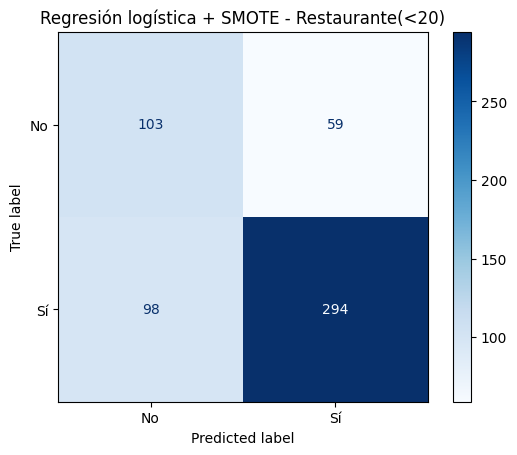

=== Árbol de decisión + SMOTE - Restaurante(<20) ===
Mejores hiperparámetros: {'modelo__criterion': 'entropy', 'modelo__max_depth': 3, 'modelo__min_samples_leaf': 10}
F1 macro en validación cruzada: 0.672
F1 macro en entrenamiento:      0.668



,params,mean_test_score,std_test_score,rank_test_score
32,"{'modelo__criterion': 'entropy', 'modelo__max_...",0.671839,0.005084,1
30,"{'modelo__criterion': 'entropy', 'modelo__max_...",0.671428,0.005425,2
31,"{'modelo__criterion': 'entropy', 'modelo__max_...",0.671428,0.005425,2
33,"{'modelo__criterion': 'entropy', 'modelo__max_...",0.669082,0.007887,4
2,"{'modelo__criterion': 'gini', 'modelo__max_dep...",0.667517,0.009756,5


              precision    recall  f1-score   support

          No      0.519     0.586     0.551       162
          Sí      0.819     0.776     0.797       392

    accuracy                          0.720       554
   macro avg      0.669     0.681     0.674       554
weighted avg      0.732     0.720     0.725       554



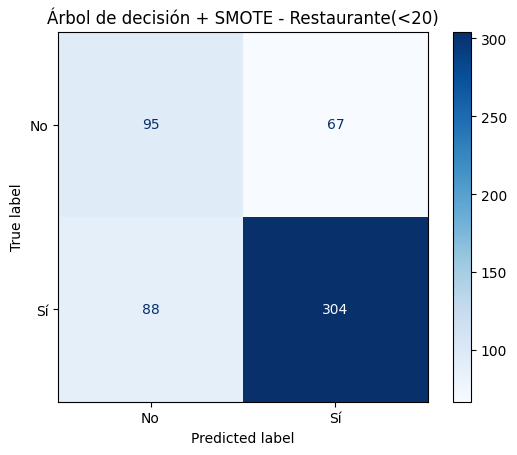

=== Random Forest + SMOTE - Restaurante(<20) ===
Mejores hiperparámetros: {'modelo__max_depth': None, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 200}
F1 macro en validación cruzada: 0.706
F1 macro en entrenamiento:      0.999



,params,mean_test_score,std_test_score,rank_test_score
13,"{'modelo__max_depth': None, 'modelo__min_sampl...",0.706133,0.010701,1
12,"{'modelo__max_depth': None, 'modelo__min_sampl...",0.699769,0.011464,2
17,"{'modelo__max_depth': None, 'modelo__min_sampl...",0.694540,0.012264,3
7,"{'modelo__max_depth': 10, 'modelo__min_samples...",0.694253,0.008250,4
9,"{'modelo__max_depth': 10, 'modelo__min_samples...",0.693271,0.010397,5


              precision    recall  f1-score   support

          No      0.652     0.463     0.542       162
          Sí      0.802     0.898     0.847       392

    accuracy                          0.771       554
   macro avg      0.727     0.680     0.694       554
weighted avg      0.758     0.771     0.758       554



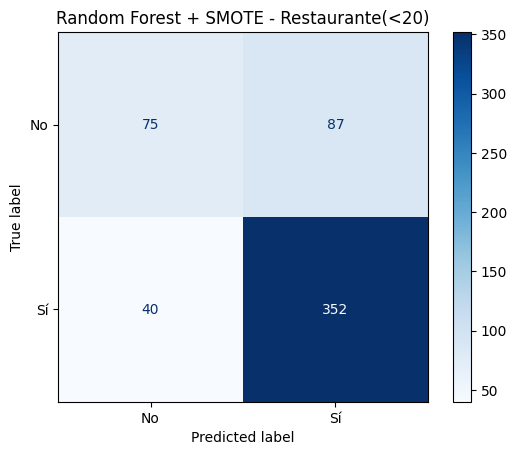

In [42]:
from sklearn.base import clone

# Evita duplicados en la lista de resultados si se vuelve a ejecutar esta celda
resultados[:] = [r for r in resultados if 'SMOTE' not in r['Modelo']]

modelos_smote = {
    'Regresión logística': (LogisticRegression(max_iter=5000, random_state=42), param_grid_lr),
    'Árbol de decisión': (DecisionTreeClassifier(random_state=42), param_grid_dt),
    'Random Forest': (RandomForestClassifier(random_state=42), param_grid_rf),
}

datos_rest = (X_rest_train, X_rest_test, y_rest_train, y_rest_test)

for nombre, (estimador, grilla) in modelos_smote.items():
    pipe_smote = ImbPipeline([
        ('preprocesador', preprocessor),
        ('smote', SMOTE(random_state=42)),
        ('modelo', clone(estimador))
    ])
    entrenar_y_evaluar('Restaurante(<20)', f'{nombre} + SMOTE', pipe_smote, grilla, datos_rest)

## 7.1 Comparación con y sin balanceo

La tabla reúne, para cada algoritmo, los resultados sobre el conjunto de prueba sin balanceo y con SMOTE. Además del F1 macro y del recall de "No", se incluye el F1 macro de validación cruzada, que es una estimación más estable que la de prueba (solo 162 registros de la clase "No").

,Algoritmo,Técnica,F1 macro (CV),F1 macro,Recall (No),Precisión (No),F1 (No),Recall (Sí)
0,Random Forest,Sin balanceo,0.700,0.685,0.420,0.680,0.519,0.918
1,Random Forest,Con SMOTE,0.706,0.694,0.463,0.652,0.542,0.898
2,Regresión logística,Sin balanceo,0.674,0.677,0.401,0.677,0.504,0.921
3,Regresión logística,Con SMOTE,0.686,0.678,0.636,0.512,0.567,0.750
4,Árbol de decisión,Sin balanceo,0.674,0.662,0.414,0.604,0.491,0.888
5,Árbol de decisión,Con SMOTE,0.672,0.674,0.586,0.519,0.551,0.776


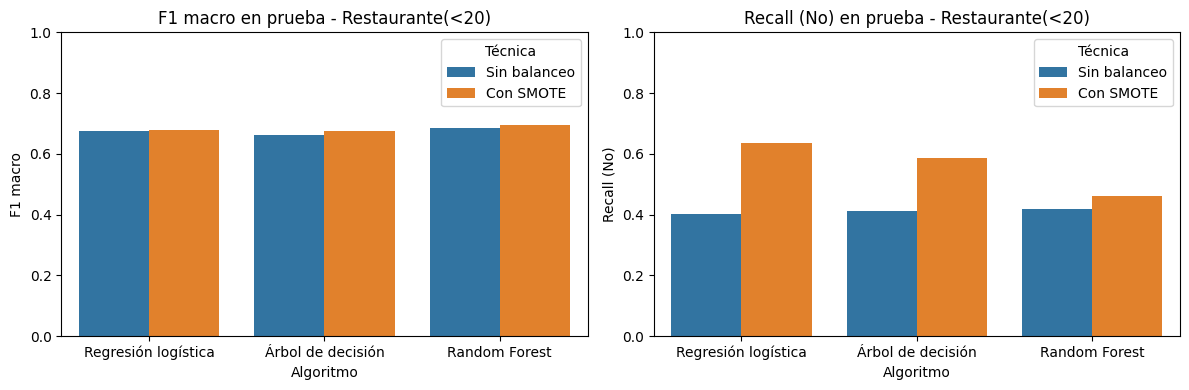

In [43]:
df_res = pd.DataFrame(resultados)
df_cmp = df_res[df_res['Cupón'] == 'Restaurante(<20)'].copy()

df_cmp['Algoritmo'] = df_cmp['Modelo'].str.replace(' + SMOTE', '', regex=False)
df_cmp['Técnica'] = np.where(df_cmp['Modelo'].str.contains('SMOTE'), 'Con SMOTE', 'Sin balanceo')
df_cmp['F1 macro (CV)'] = [modelos[('Restaurante(<20)', m)].best_score_ for m in df_cmp['Modelo']]

cols = ['Algoritmo', 'Técnica', 'F1 macro (CV)', 'F1 macro', 'Recall (No)', 'Precisión (No)', 'F1 (No)', 'Recall (Sí)']
tabla_cmp = df_cmp[cols].sort_values(['Algoritmo', 'Técnica'], ascending=[True, False]).round(3)
display(tabla_cmp.reset_index(drop=True))

# Gráfico: F1 macro y recall de "No", con y sin SMOTE
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metrica in zip(axes, ['F1 macro', 'Recall (No)']):
    sns.barplot(data=df_cmp, x='Algoritmo', y=metrica, hue='Técnica', ax=ax)
    ax.set_title(f'{metrica} en prueba - Restaurante(<20)')
    ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

In [44]:
for nombre in modelos_smote:
    sin = modelos[('Restaurante(<20)', nombre)]
    con = modelos[('Restaurante(<20)', f'{nombre} + SMOTE')]
    print(f'{nombre}\n  Sin balanceo: {sin.best_params_}\n  Con SMOTE:    {con.best_params_}\n')

Regresión logística
  Sin balanceo: {'modelo__C': 0.2, 'modelo__penalty': 'l1', 'modelo__solver': 'liblinear'}
  Con SMOTE:    {'modelo__C': 0.15, 'modelo__penalty': 'l1', 'modelo__solver': 'liblinear'}

Árbol de decisión
  Sin balanceo: {'modelo__criterion': 'entropy', 'modelo__max_depth': 7, 'modelo__min_samples_leaf': 50}
  Con SMOTE:    {'modelo__criterion': 'entropy', 'modelo__max_depth': 3, 'modelo__min_samples_leaf': 10}

Random Forest
  Sin balanceo: {'modelo__max_depth': None, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 200}
  Con SMOTE:    {'modelo__max_depth': None, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 200}



**Análisis - Efecto de SMOTE en Restaurante(<20).**

*Qué cambió con SMOTE.*
- **El recall de "No" sube en los tres modelos, pero de forma muy desigual:** +0.235 puntos en regresión logística (0.401 -> 0.636), +0.172 en el árbol (0.414 -> 0.586) y solo +0.043 en Random Forest (0.420 -> 0.463).
- **Ese aumento tiene un costo.** En regresión logística la precisión de "No" cae de 0.677 a 0.512 y el recall de "Sí" de 0.921 a 0.750. En el árbol, la precisión de "No" baja de 0.604 a 0.519 y el recall de "Sí" de 0.888 a 0.776. La exactitud también cae (0.769 -> 0.717 en regresión logística y 0.749 -> 0.720 en el árbol). Es decir, el modelo detecta más rechazos, pero a cambio etiqueta como rechazo a más conductores que sí habrían aceptado.
- **El F1 macro casi no se mueve:** en prueba cambia +0.001 (regresión logística), +0.012 (árbol) y +0.009 (Random Forest). En validación cruzada, +0.012, -0.002 y +0.006 respectivamente, todos dentro de una desviación estándar entre particiones (entre 0.005 y 0.017). Con solo 162 registros de la clase "No" en prueba, diferencias de este tamaño no son concluyentes.

SMOTE no aporta información nueva sobre qué conductores rechazan: genera registros sintéticos a partir de los existentes, y lo que hace en la práctica es intercambiar errores de un tipo por errores del otro (menos rechazos no detectados, más aceptaciones clasificadas como rechazo) sin que mejore la calidad global. El caso de Random Forest lo ilustra bien: con ramas sin restricción de profundidad ni de tamaño de hoja (`max_depth=None`, `min_samples_leaf=1`), los árboles pueden aislar los puntos sintéticos y el efecto sobre la votación es pequeño. En la matriz de confusión, el bosque detecta 7 rechazos más (68 -> 75) y pierde 8 aceptaciones más (32 -> 40): el total de errores prácticamente no cambia (126 -> 127). Además, SMOTE obligó al árbol a elegir una configuración más simple (`max_depth = 3`, `min_samples_leaf = 10` en lugar de 7 y 50), sin ganancia en validación.

*Recomendación:* **No se justifica aplicar SMOTE para mejorar el desempeño global**: no mejora de forma significativa el F1 macro en ningún modelo y añade complejidad. Su valor está en otro lado: sirve cuando Ruta Alpes quiera **priorizar la detección de conductores que rechazarán el cupón**, por ejemplo para evitar notificaciones irrelevantes, que el caso identifica como una fuente de molestia. En ese escenario, la regresión logística con SMOTE (recall de "No" de 0.636) es la mejor opción, a costa de perder aceptaciones potenciales (recall de "Sí" de 0.750). 

Como la decisión depende del costo relativo de cada error para el negocio, la mejor forma de entender el uso de SMOTE es como un compromiso y no como una mejora. Para el modelo final de Restaurante(<20), el Random Forest sigue siendo la mejor opción con o sin SMOTE; la diferencia entre ambas versiones (F1 macro 0.685 contra 0.694) es marginal.

# 8. Comparación de modelos y selección del mejor por cupón

Se compara el desempeño sobre el **conjunto de prueba** de los tres algoritmos (regresión logística, árbol de decisión y Random Forest) para cada tipo de cupón, con precisión, recall y F1-score de cada clase. Se incluye además el F1 macro, que resume el desempeño en ambas clases, y el F1 macro de validación cruzada.

**Criterio de selección.** El mejor modelo se elige con el **F1 macro de validación cruzada**, no con el de prueba: así el conjunto de prueba se conserva como una evaluación independiente y no se usa para decidir. El resultado en prueba sirve para confirmar y para reportar. En Restaurante(<20) se tiene además en cuenta el recall de la clase minoritaria ("No").

Los modelos con SMOTE se excluyen de esta tabla porque ya se analizaron en la sección anterior, donde se concluyó que no mejoran de forma significativa el desempeño global.

In [45]:
df_res = pd.DataFrame(resultados)
base = df_res[~df_res['Modelo'].str.contains('SMOTE')].copy()   # solo los tres algoritmos base

base['F1 macro (CV)'] = [modelos[(c, m)].best_score_ for c, m in zip(base['Cupón'], base['Modelo'])]

orden = ['Regresión logística', 'Árbol de decisión', 'Random Forest']
base['Modelo'] = pd.Categorical(base['Modelo'], categories=orden, ordered=True)

cols = ['Precisión (Sí)', 'Recall (Sí)', 'F1 (Sí)',
        'Precisión (No)', 'Recall (No)', 'F1 (No)',
        'F1 macro', 'F1 macro (CV)']

for cupon in ['Cafetería', 'Restaurante(<20)']:
    print(f'=== {cupon} (resultados en prueba; en morado, el mejor valor de cada columna) ===')
    t = base[base['Cupón'] == cupon].sort_values('Modelo').set_index('Modelo')[cols]
    display(t.style.format('{:.3f}').highlight_max(axis=0, color='purple'))

=== Cafetería (resultados en prueba; en morado, el mejor valor de cada columna) ===


,Precisión (Sí),Recall (Sí),F1 (Sí),Precisión (No),Recall (No),F1 (No),F1 macro,F1 macro (CV)
Modelo,,,,,,,,
Regresión logística,0.698,0.720,0.709,0.712,0.689,0.701,0.705,0.721
Árbol de decisión,0.672,0.718,0.694,0.699,0.652,0.674,0.684,0.715
Random Forest,0.775,0.796,0.785,0.791,0.769,0.780,0.783,0.757


=== Restaurante(<20) (resultados en prueba; en morado, el mejor valor de cada columna) ===


,Precisión (Sí),Recall (Sí),F1 (Sí),Precisión (No),Recall (No),F1 (No),F1 macro,F1 macro (CV)
Modelo,,,,,,,,
Regresión logística,0.788,0.921,0.849,0.677,0.401,0.504,0.677,0.674
Árbol de decisión,0.786,0.888,0.834,0.604,0.414,0.491,0.662,0.674
Random Forest,0.793,0.918,0.851,0.680,0.420,0.519,0.685,0.700


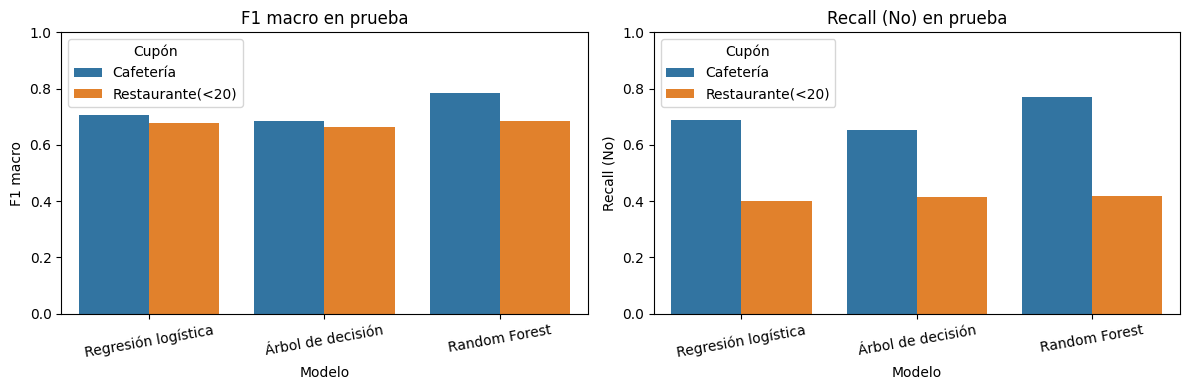

,Cupón,Modelo,F1 macro (CV),F1 macro
0,Cafetería,Random Forest,0.757,0.783
1,Restaurante(<20),Random Forest,0.700,0.685


In [46]:
# Gráfico comparativo
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metrica in zip(axes, ['F1 macro', 'Recall (No)']):
    sns.barplot(data=base, x='Modelo', y=metrica, hue='Cupón', ax=ax)
    ax.set_title(f'{metrica} en prueba')
    ax.set_ylim(0, 1)
    ax.tick_params(axis='x', rotation=10)
plt.tight_layout()
plt.show()

# Selección del mejor modelo por cupón con F1 macro de validación cruzada
seleccion = base.loc[base.groupby('Cupón')['F1 macro (CV)'].idxmax(),
                     ['Cupón', 'Modelo', 'F1 macro (CV)', 'F1 macro']]
display(seleccion.reset_index(drop=True).round(3))

# Guardar los modelos seleccionados para las siguientes actividades
mejores = {fila['Cupón']: modelos[(fila['Cupón'], fila['Modelo'])] for _, fila in seleccion.iterrows()}

**Análisis comparativo.**

*Cafetería.*
- El **Random Forest** es el mejor modelo en todas las métricas, con F1 macro de 0.783 en prueba (0.757 en validación cruzada). Le siguen la regresión logística (0.705) y el árbol de decisión (0.684).
- La ventaja es amplia (unos 8 puntos sobre la regresión logística y 10 sobre el árbol) y consistente entre validación y prueba, así que no es un efecto del azar.
- Al estar las clases balanceadas, el desempeño es parejo entre "Sí" y "No" en los tres modelos, y las diferencias entre precisión y recall son pequeñas. La selección es clara.

*Restaurante(<20).*
- El **Random Forest** vuelve a ser el mejor, con F1 macro de 0.685 en prueba y 0.700 en validación cruzada, frente a 0.677 y 0.674 de la regresión logística y 0.662 y 0.674 del árbol.
- La ventaja es **más modesta** que en Cafetería: 0.8 puntos sobre la regresión logística en prueba y 2.6 puntos en validación cruzada. Con 554 registros de prueba (162 de la clase "No"), la diferencia en prueba no es concluyente por sí sola; la selección se apoya sobre todo en la validación cruzada, que usa muchos más datos de entrenamiento.
- Los tres modelos son **igual de malos detectando los rechazos**: el recall de "No" está entre 0.401 y 0.420. Ningún algoritmo resuelve el problema de la clase minoritaria; el Random Forest es solo ligeramente mejor, con la mayor precisión de "No" (0.680) y el mayor F1 de "No" (0.519).

*Diferencia entre cupones.* El mejor modelo rinde mucho mejor en Cafetería (F1 macro 0.783) que en Restaurante(<20) (0.685). El desbalance de clases explica parte de la diferencia, pero no toda: aun con SMOTE el desempeño en Restaurante(<20) apenas mejora, lo que sugiere que las variables disponibles explican menos la decisión en ese cupón.

*Selección final.* Se escoge el **Random Forest para ambos cupones**. Es el de mejor desempeño en validación y en prueba en los dos casos. Como contrapartida, es menos interpretable que una regresión logística o un árbol y más costoso de ejecutar; si Ruta Alpes prioriza explicar cada recomendación, la regresión logística es una alternativa razonable en Restaurante(<20), donde la ventaja del bosque es pequeña. Para Restaurante(<20) se usa el modelo **sin SMOTE**, porque la mejora que aporta (F1 macro 0.694 contra 0.685) no es significativa y no justifica los datos sintéticos.

# 9. Variables más relevantes

Para identificar qué factores del contexto o del perfil del conductor influyen más en cada cupón se analiza el **mejor modelo de cada uno (Random Forest)** con dos medidas de importancia: la importancia por permutación (medida principal) y la importancia por impureza (medida de contraste). En ambos casos se obtiene **un valor por variable original**, no por cada columna del one-hot encoder.

## 9.1 Importancia por permutación

Sobre el conjunto de prueba se mezcla al azar una variable a la vez, rompiendo su relación con la aceptación del cupón, y se mide cuánto cae el F1 macro. Cuanto mayor la caída, más depende el modelo de esa variable. El procedimiento se repite 10 veces por variable y se reporta la media y la desviación estándar. Se aplica al pipeline completo, por lo que se permutan las variables originales.

Un valor cercano a cero o negativo indica que el modelo no pierde nada cuando esa variable se mezcla. Una variable se considera claramente informativa si su media supera dos veces su desviación estándar (columna `señal clara`). Mide qué usa el modelo para predecir.

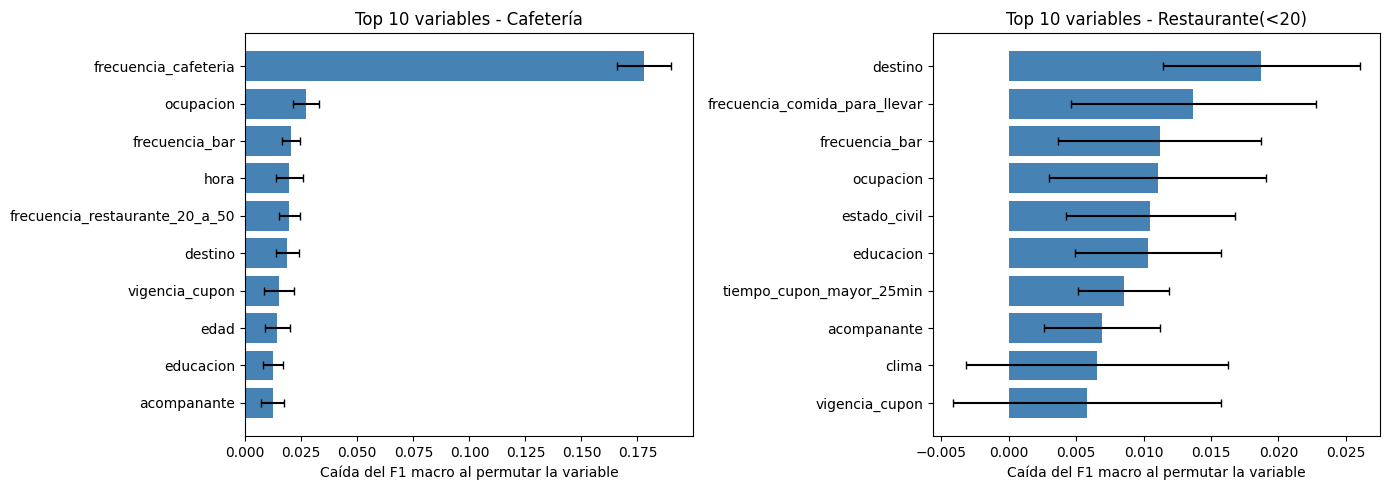

=== Cafetería ===


,media,std,señal clara
frecuencia_cafeteria,0.1780,0.0121,True
ocupacion,0.0271,0.0059,True
frecuencia_bar,0.0205,0.0041,True
hora,0.0197,0.0061,True
frecuencia_restaurante_20_a_50,0.0196,0.0047,True
destino,0.0187,0.0051,True
vigencia_cupon,0.0151,0.0066,True
edad,0.0143,0.0057,True
educacion,0.0124,0.0046,True
acompanante,0.0123,0.0051,True


=== Restaurante(<20) ===


,media,std,señal clara
destino,0.0187,0.0073,True
frecuencia_comida_para_llevar,0.0137,0.0091,False
frecuencia_bar,0.0112,0.0075,False
ocupacion,0.0110,0.0080,False
estado_civil,0.0105,0.0063,False
educacion,0.0103,0.0054,False
tiempo_cupon_mayor_25min,0.0085,0.0034,True
acompanante,0.0069,0.0043,False
clima,0.0065,0.0097,False
vigencia_cupon,0.0058,0.0099,False


In [47]:
from sklearn.inspection import permutation_importance

test_sets = {
    'Cafetería': (X_cafe_test, y_cafe_test),
    'Restaurante(<20)': (X_rest_test, y_rest_test),
}

def importancia_permutacion(cupon, n_repeticiones=10):
    modelo = mejores[cupon].best_estimator_
    Xte, yte = test_sets[cupon]
    r = permutation_importance(modelo, Xte, yte, scoring='f1_macro',
                               n_repeats=n_repeticiones, random_state=42, n_jobs=-1)
    df = pd.DataFrame({'media': r.importances_mean, 'std': r.importances_std}, index=Xte.columns)
    df['señal clara'] = df['media'] > 2 * df['std']
    return df.sort_values('media', ascending=False)

importancias = {c: importancia_permutacion(c) for c in mejores}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (cupon, df) in zip(axes, importancias.items()):
    top = df.head(10).iloc[::-1]
    ax.barh(top.index, top['media'], xerr=top['std'], color='steelblue', capsize=3)
    ax.set_title(f'Top 10 variables - {cupon}')
    ax.set_xlabel('Caída del F1 macro al permutar la variable')
plt.tight_layout()
plt.show()

for cupon, df in importancias.items():
    print(f'=== {cupon} ===')
    display(df.round(4))

## 9.2 Importancia por impureza (contraste)

El Random Forest ofrece también una medida interna, `feature_importances_`: cuánto reduce cada variable la impureza de las clases a lo largo de todas las divisiones de todos los árboles. Se suma la importancia de las columnas resultantes de aplicar el one-hot encoder de cada variable original para compararla con la permutación.

Esta medida se calcula con los datos de entrenamiento y tiende a sobrevalorar las variables con muchas categorías, que ofrecen más puntos de corte posibles. Por eso se usa solo como contraste de la permutación, que se calcula sobre datos no vistos.

In [48]:
def variable_original(nombre_columna, columnas_originales):
    n = nombre_columna.split('__', 1)[1]
    candidatas = [c for c in columnas_originales if n == c or n.startswith(c + '_')]
    return max(candidatas, key=len)   # la más larga evita confundir nombres que comparten prefijo

def importancia_impureza(cupon, columnas):
    pipe = mejores[cupon].best_estimator_
    nombres = pipe.named_steps['preprocesador'].get_feature_names_out()
    imp = pd.Series(pipe.named_steps['modelo'].feature_importances_, index=nombres)
    return imp.groupby([variable_original(n, columnas) for n in imp.index]).sum()

columnas = {'Cafetería': X_cafe_train.columns, 'Restaurante(<20)': X_rest_train.columns}

for cupon in ['Cafetería', 'Restaurante(<20)']:
    perm = importancias[cupon]['media']
    imp = importancia_impureza(cupon, columnas[cupon])
    t = pd.DataFrame({'Permutación (media)': perm, 'Rango permutación': perm.rank(ascending=False).astype(int),
                      'Impureza': imp, 'Rango impureza': imp.rank(ascending=False).astype(int)})
    print(f'=== {cupon} ===')
    display(t.sort_values('Rango permutación').head(10).round(3))

=== Cafetería ===


,Permutación (media),Rango permutación,Impureza,Rango impureza
frecuencia_cafeteria,0.178,1,0.144,1
ocupacion,0.027,2,0.113,2
frecuencia_bar,0.020,3,0.053,7
hora,0.020,4,0.056,5
frecuencia_restaurante_20_a_50,0.020,5,0.049,9
destino,0.019,6,0.033,14
vigencia_cupon,0.015,7,0.039,12
edad,0.014,8,0.073,4
educacion,0.012,9,0.056,6
acompanante,0.012,10,0.038,13


=== Restaurante(<20) ===


,Permutación (media),Rango permutación,Impureza,Rango impureza
destino,0.019,1,0.039,15
frecuencia_comida_para_llevar,0.014,2,0.056,7
frecuencia_bar,0.011,3,0.055,8
ocupacion,0.011,4,0.117,1
estado_civil,0.011,5,0.045,11
educacion,0.010,6,0.060,6
tiempo_cupon_mayor_25min,0.009,7,0.024,16
acompanante,0.007,8,0.042,13
clima,0.007,9,0.041,14
vigencia_cupon,0.006,10,0.043,12


## 9.3 Análisis

**Cafetería.**
- Una variable domina con claridad: `frecuencia_cafeteria`. Al permutarla, el F1 macro cae 0.178, más de seis veces lo que cae con la segunda variable (`ocupacion`, 0.0271). Por impureza también ocupa el primer lugar. En términos del negocio, el mejor predictor de si alguien acepta un cupón de cafetería es si ya consume en cafeterías.
- Detrás hay un grupo de variables con aportes pequeños: hábitos de consumo (`frecuencia_bar`, `frecuencia_restaurante_20_a_50`, `frecuencia_restaurante_menos_20`), contexto de la oferta (`hora`, `destino`, `vigencia_cupon`) y perfil (`ocupacion`, `edad`, `educacion`).
- Dentro del ruido (sin señal clara) quedan `tiempo_cupon_mayor_25min`, `tiene_hijos`, `clima`, `genero`, `estado_civil` y `frecuencia_comida_para_llevar`. `tiempo_cupon_mayor_25min` es probablemente redundante con `tiempo_cupon_mayor_15min`: si el cupón está a más de 25 minutos, también está a más de 15.

**Restaurante(<20).**
- Ninguna variable domina. La más importante es `destino` (aprox. 0.019), seguida de `frecuencia_comida_para_llevar` (aporx. 0.014), pero la mayoría tiene una media comparable a su desviación estándar. Solo `destino` y `tiempo_cupon_mayor_25min` superan claramente el ruido.
- Varias variables tienen importancia nula o negativa (`genero`, `misma_direccion`, `tiene_hijos`, `frecuencia_restaurante_menos_20`, `temperatura`): mezclarlas no perjudica al modelo, así que son poco informativas. Llama la atención que el hábito de comer en restaurantes baratos, el predictor natural de este cupón, no aporte, mientras que en Cafetería el hábito equivalente lo explica casi todo.

**Comparación entre cupones.** En Cafetería hay una variable altamente influyente (`frecuencia_cafeteria`); en Restaurante(<20) la señal es débil y está repartida entre muchas variables. Esto ayuda a explicar por qué los modelos rinden peor en Restaurante(<20): las variables disponibles describen poco la decisión de aceptar este cupón.

**Síntesis para Ruta Alpes.** En Cafetería el factor decisivo es el hábito del conductor. En Restaurante(<20) no hay un factor dominante y pesan más las circunstancias del viaje (destino y tiempo disponible) que los hábitos o la demografía. La personalización puede apoyarse sobre todo en el contexto del viaje, que se observa en tiempo real y no es sensible.

# 10. Analisis de resultados

**1. ¿Qué características del contexto de conducción o del perfil del conductor parecen estar más relacionadas con la aceptación de cada tipo de cupón?**

En ambos cupones las variables demograficas no tienen tanta relacion con la aceptacion, en estas pesan mas el contexto del viaje y en cafeteria el habito de consumo. Para cafeteria el factor mas relacionado es el habito del conductor de ir a cafeterias ya que quienes nunca van aceptan el cupon solo el 19% a comparacion del 65% y 69% de los que van al menos entre una y tres veces al mes y esto lo vemos en el Random Forest donde es la variable dominante y que al permutarla, el F1 macro cae 0,178 que es mucho mas de la segunda variable que es ocupacion con 0,027. Detras de estas esta otro grupo de variables pero que no tienen tanto aporte como los otros habitos de consumo, el contexto de la oferta y algo del perfil del conductor. Algo a mencionar es que durante la exploracion tambien se ve que se acepta mas cuando el conductor no tiene un lugar urgente adonde ir que tiene un 58% frente a 36% cuando va a la casa, tambien cuando viaja con amigos, a las 10 am (64 %) y con cupones de 1 dia que tiene 58% frente a 43% con los de 2 horas.

Para el restaurante(<20) no hay una variable dominante como tal y las unicas con una señal clara en la importancia por permutacion son `destino` que es la mas importante, con una caida cerca de 0,019 en el F1 macro y `tiempo_cupon_mayor_25min` que cuando el establecimiento queda a mas de 25 minutos la aceptacion cae a 33%, y precisamente este es el primer criterio de division del arbol de decision. Otras variables de contexto tambien muestran diferencias que se evidencian en la exploracion, como el clima soleado con 77% de aceptación frente a 39% con lluvia, la hora y la vigencia del cupon (83% con 1 dia frente a 59% con 2 horas), aunque su aporte en el modelo es pequeño. Algo que llama la atencion es que el habito de comer en restaurantes baratos, que en principio es predictor natural de este cupon, no aporta casi al modelo a pesar de que su relacion con la aceptacion se ve en la exploración con un 56% si nunca van frente a 76% si van mas de 8 veces.

**2. ¿Existen variables que podrían ser redundantes o poco informativas?**

**Las variables eliminadas en la preparacion de la seccion 3:** Tenemos aqui a `vehiculo` que tiene cerca del 99% de valores nulos en ambos subconjuntos por lo que no se puede usar, tambien `cupon` y `tiempo_cupon_mayor_5min` donde todos los registros tienen el mismo valor, asi que no pueden sacar concusiones en la aceptacion. Por ultimo `direccion_opuesta` es el complemento exacto de `misma_direccion` por lo que repite la misma informacion.

**Variables parcialmente redundantes que se conservaron:** Las variables `tiempo_cupon_mayor_15min` y `tiempo_cupon_mayor_25min` estan anidadas ya que si el establecimiento queda a mas de 25 minutos tambien queda a mas de 15. En cafeteria, `tiempo_cupon_mayor_25min` no muestra señal clara en el modelo por lo que `tiempo_cupon_mayor_15min` ya recoge la mayor parte de esa informacion. Ademas, `temperatura` esta muy ligada a `clima` doned con clima nevado solo aparece 30 y con clima lluvioso 55, aqui se dejaron ambas porque no son equivalentes y porque la preparacion no pretendia descartar variables con base en suposiciones.

**Variables poco informativas en el modelo:** Al permutarlas el F1 macro del Random Forest no cambia a simple vista. En cafeteria no muestran señal clara `tiene_hijos`, `clima`, `genero`, `estado_civil` y `frecuencia_comida_para_llevar`. En Restaurante(<20) tienen importancia nula `genero`, `misma_direccion`, `tiene_hijos`, `frecuencia_restaurante_menos_20` y `temperatura`. Las que coinciden en ambos cupones son `genero` y `tiene_hijos` lo que confirma lo que se veia en la exploracion donde la aceptacion casi no cambia entre hombres y mujeres ni entre quienes tienen o no hijos.

Ahora bien, el hecho de que una variable tenga poca importancia por permutacion no signifique que sea basura ya que si dos variables comparten informacion, al permutar una el modelo se apoya en la otra y ambas parecen poco importantes (como `clima`y `temperatura`). Además, `ocupacion` tiene 25 categorias y estas mismas que tienen varias categorias pueden recibir mas importancia por impureza de la que merecen.

**3. ¿El desempeño y el comportamiento de los modelos difieren entre Cafetería y Restaurante(<20)? Si es así, ¿a qué atribuye esa diferencia?**

| Modelo | Cafetería: F1 macro | Restaurante(<20): F1 macro | Restaurante(<20): recall de "No" |
|---|---|---|---|
| Regresión logística | 0,705 (0,721) | 0,677 (0,674) | 0,401 |
| Árbol de decisión | 0,684 (0,715) | 0,662 (0,674) | 0,414 |
| Random Forest | 0,783 (0,757) | 0,685 (0,700) | 0,420 |

- **Nivel de desempeño:** el mejor modelo que es el Random Forest alcanza 0,783 en cafeteria pero solo 0,685 en Restaurante(<20), una diferencia de casi 10 puntos.
- **Ventaja del Random Forest:** en cafeteria supera a la regresion logistica por unos 8 puntos y a los arboles por unos 10, y esa ventaja se confirma en validacion cruzada. En Restaurante(<20) la ventaja es de apenas 0,8 puntos en prueba y 2,6 en validacion cruzada, lo cual con 554 registros de prueba no es concluyente.
- **Desbalance de clases:** cafeteria está balanceada con 49,9% en "Sí" y 50,1% en "No", mientras que Restaurante(<20) tiene 70,7% de "Sí", siendo asi los modelos no aprenden tanto sobre quien rechaza el cupon y se inclinan hacia la clase mayoritaria.
- **Cantidad de señal en las variables:** En cafeteria una variable domina que es `frecuencia_cafeteria` y al permutarla, el F1 macro cae 0,178. En Restaurante(<20) ninguna variable domina y la señal esta repartida entre muchas donde cada da un aporte pequeño por lo que se vuelve mas dificil predecir.

La relacion entre variables es que en cafeteria, el bosque supera por mucho a los modelos mas simples, lo que sugiere que la aceptacion depende de combinaciones de factores. El balanceo con SMOTE nos confirma que el desbalance explica solo una parte en donde aumento el recall de "No" pero casi no cambio el F1 macro porque cambio el tipo de error y no la calidad global.

**4. ¿Aplicar balanceo de clases en Restaurante(<20) mejoró el modelo? Justifique considerando tanto el F1-score general, así como el recall de la clase minoritaria.**

Si mejoro el recall de "No" ya que con SMOTE los modelos detectan mas conductores que rechazarian el cupon, aqui la mejora es grande en la regresion logistica y en el arbol, y pequeña en Random Forest pero no mejoro de forma significativa el F1 general donde cambio entre +0,001 y +0,012 en prueba, y en validacion cruzada las diferencias quedan dentro de una desviacion estandar entre particiones. SMOTE cambio como tal el tipo de errores que comete el modelo y no la calidad global.

| Modelo | Recall de "No" sin SMOTE | Recall de "No" con SMOTE | F1 macro sin SMOTE | F1 macro con SMOTE |
|---|---|---|---|---|
| Regresión logistica | 0,401 | 0,636 (+0,235) | 0,677 | 0,678 (+0,001) |
| Arbol de decision | 0,414 | 0,586 (+0,172) | 0,662 | 0,674 (+0,012) |
| Random Forest | 0,420 | 0,463 (+0,043) | 0,685 | 0,694 (+0,009) |

**5. Descripción de las características que llevan a aceptar o rechazar un cupón (Random Forest) y utilidad y limitación de esta interpretación**

Como vimos, el Random Forest es el mejor modelo de cada cupon, este se interpreta con la importancia por permutacion y se verifica la direccion del efecto con la tasa de aceptacion por categoria.

En cafeteria la aceptacion depende sobre todo del habito de consumo:

| Variable | Importancia | Que lleva a aceptar o rechazar |
|---|---|---|
| `frecuencia_cafeteria` | 0,178 | Aceptan 66 a 69% quienes van a cafeterias 1 vez al mes o mas, quienes van menos de 1 vez acepta 48% y entre quienes nunca van solo 19%. |
| `ocupacion` | 0,027 | Varia por grupo, por ejemplo 74% en profesionales de la salud y 63% en estudiantes. |

Restaurante(<20) donde no hay una variable dominante:

| Variable | Importancia | Qué lleva a aceptar o rechazar |
|---|---|---|
| `destino` | 0,019 | acepta 79%. Trabajo: 59%. Casa: 56%. |
| `tiempo_cupon_mayor_25min` | 0,009 | Si el restaurante esta a mas de 25 min acepta solo 33%, si no 76%. |
| `frecuencia_comida_para_llevar` | 0,014 | Quienes piden comida para llevar a menudo aceptan mas (70 a 77% frente a 61% en quienes piden menos de 1 vez). |

Aqui acepta quien no tiene un destino urgente y si el restaurante queda cerca.

Con respecto a la utilidad, se permite saber en que fijarse ya que a Ruta Alpes le basta con `frecuencia_cafeteria` para saber a quien ofrecerle cupones de cafeteria mientras que para el restaurante con `destino` y la distancia.

Las limitaciones que se presentan:
- La permutacion dice cuanto usa el modelo una variable y no si la sube o la baja. La direccion se saco aparte con tasas de aceptacion.
- Variables correlacionadas se reparten o se ocultan la importancia, como por ejemplo `tiempo_cupon_mayor_15min` y `tiempo_cupon_mayor_25min` estan anidadas y sus valores individuales subestiman el efecto conjunto.
- Es una medida global y no explica por que un conductor en concreto rechazo un cupon, y puede ocultar interacciones.



**6. ¿Cómo podría integrarse este tipo de modelo en una aplicación de conducción para decidir en tiempo real qué cupón mostrar?**

Aqui el modelo se guarda como un servicio de prediccion que la aplicacion consulta cada vez que hay una oportunidad de mostrar un cupon:

1. **Entrada:** La aplicacion envia al servicio el contexto del momento tipo el destino, acompañante, clima, etc junto con el perfil y los habitos del conductor que ya estan guardados en su cuenta.
2. **Prediccion:** El servicio carga el pipeline entrenado, y asi las transformaciones son las mismas del entrenamiento.
3. **Puntuacion por cupon.** Con `predict_proba` se calcula la probabilidad de aceptacion para cada cupon disponible cerca del conductor.
4. **Decision.** Se muestra el cupon con mayor probabilidad si supera un umbral definido por el negocio y si ninguno lo supera no se muestra nada.
5. **Respuesta y retroalimentación.** El servicio devuelve la decision a la aplicacion en milisegundos ya que un Random Forest de 100 a 200 arboles predice rapido y ya la aplicacion registra si el conductor acepto o no, y son estos datos los que alimentan el reentrenamiento.

Las condiciones para que esto funcione bien serian monitorear el desempeño en produccion y reentrenar cuando cambien los habitos de los conductores y mostrar el cupon solo cuando sea seguro, osea cuando el vehiculo este detenido o con alerta no intrusiva.

**7. ¿Qué limitaciones tendría un sistema automático que decide qué ofertas mostrar a cada conductor según su perfil demográfico?**

- **Datos limitados y sesgados:** El modelo aprendio de una encuesta de alrededor de 12.600 respuestas, esa muestra puede no representar a todos los conductores y en Restaurante(<20) el modelo apenas supera el 0,69 de F1 macro.
- Dos conductores con el mismo perfil pueden decidir de manera distinta segun el momento. Las variables de contexto como `destino` y la distancia pesan tanto o incluso mas que las demograficas.
- **Errores sin supervisión:** Un falso positivo puede mostrar una oferta irrelevante y un falso negativo hace perder una venta sin que nadie lo revise.
- **Caducidad del modelo:** Los habitos y el contexto cambian, esto sin monitoreo ni reentrenamiento el modelo puede perder desempeño.
- **Privacidad y consentimiento:** Usar el perfil demografico exige datos personales que requieren autorizacion y proteccion.

**8. ¿Qué fuentes de sesgo podrían estar presentes al usar variables como edad, género, estado civil o ingreso para personalizar ofertas? ¿Qué implicaciones tendría usarlas para fines distintos a cupones (por ejemplo, precios dinámicos)?**

Las fuentes de sesgo son las siguientes:
- **Muestreo:** Aqui si la encuesta tiene mas respuestas de unos grupos, el modelo aprende mejor de ellos y falla mss con los demas.
- **Historicas y sociales:** los datos reflejan ciertos habitos y desigualdades existentes y con esto el modelo las utiliza como si fueran preferencias.
- **Variables proxy:** aunque se quite el genero o el ingreso, otras variables como ocupacion, educacion y frecuencia de consumo pueden codificarlos indirectamente.
- **Medicion y modelado:** las respuestas se reportan automaticamente y el desbalanceo o SMOTE pueden favorecer a unos grupos sobre otros.

Las implicaciones al usarlas en precios dinamicos conllevan riesgos legales y eticos significativos, ya que a diferencia de un error menor al ofrecer un cupon, el hecho de fijar precios mas altos para ciertos grupos puede costar dinero y ser considerado discriminatorio. Tambien el hecho de personalizar precios por rasgos puede ser ilegal e incluso visto mal desde el aspecto etico y daña la confianza del cliente.

# 11. Aplicación del modelo sobre el CSV de prueba suministrado
En esta sección se aplica el mejor modelo de cada cupon sobre el data frame de prueba.

Para aplicar el modelo sobre los datos de prueba hay que repetir la misma preparacion del entrenamiento que es eliminar las columnas `vehiculo`, `cupon`, `tiempo_cupon_mayor_5min` y `direccion_opuesta`. La imputacion de nulos, el escalado y el one-hot encoding ya estan dentro del pipeline, asi que se aplican solos al usar el metodo `predict` del mejor modelo de cada cupon.

In [49]:
df_test_copy = df_test.copy()

# Preparacion que es la misma del entrenamiento
cols_eliminar = ['vehiculo', 'cupon', 'tiempo_cupon_mayor_5min', 'direccion_opuesta']

# Prediccion con el mejor modelo de cada cupon
test_data_final = df_test.copy()
test_data_final['acepta_cupon_predicha'] = None

for cupon, modelo in mejores.items():
    mascara = df_test_copy['cupon'] == cupon
    X_nuevo = df_test_copy.loc[mascara].drop(columns=cols_eliminar)
    test_data_final.loc[mascara, 'acepta_cupon_predicha'] = modelo.predict(X_nuevo)

test_data_final.to_csv('predicciones.csv', index=False, encoding='utf-8-sig')
test_data_final.head()

,destino,acompanante,clima,temperatura,hora,cupon,vigencia_cupon,genero,edad,estado_civil,...,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_5min,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,direccion_opuesta,acepta_cupon_predicha
0,Trabajo,Solo,Soleado,55,7:00 a.m.,Cafetería,2 horas,Femenino,50 o más,Divorciado(a),...,4 a 8,4 a 8,4 a 8,menos de 1,Sí,Sí,No,No,Sí,Sí
1,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Cafetería,2 horas,Femenino,31,Unión libre,...,1 a 3,más de 8,4 a 8,1 a 3,Sí,No,No,No,Sí,Sí
2,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,2 horas,Femenino,31,Soltero(a),...,1 a 3,4 a 8,más de 8,menos de 1,Sí,Sí,No,No,Sí,Sí
3,Sin lugar urgente,Pareja,Soleado,80,10:00 a.m.,Cafetería,2 horas,Masculino,50 o más,Casado(a),...,más de 8,nunca,4 a 8,menos de 1,Sí,No,No,No,Sí,Sí
4,Sin lugar urgente,Amigo(s),Soleado,80,6:00 p.m.,Restaurante(<20),2 horas,Femenino,26,Soltero(a),...,menos de 1,4 a 8,menos de 1,4 a 8,Sí,Sí,No,No,Sí,Sí


**Validacion de las predicciones en el conjunto de prueba**

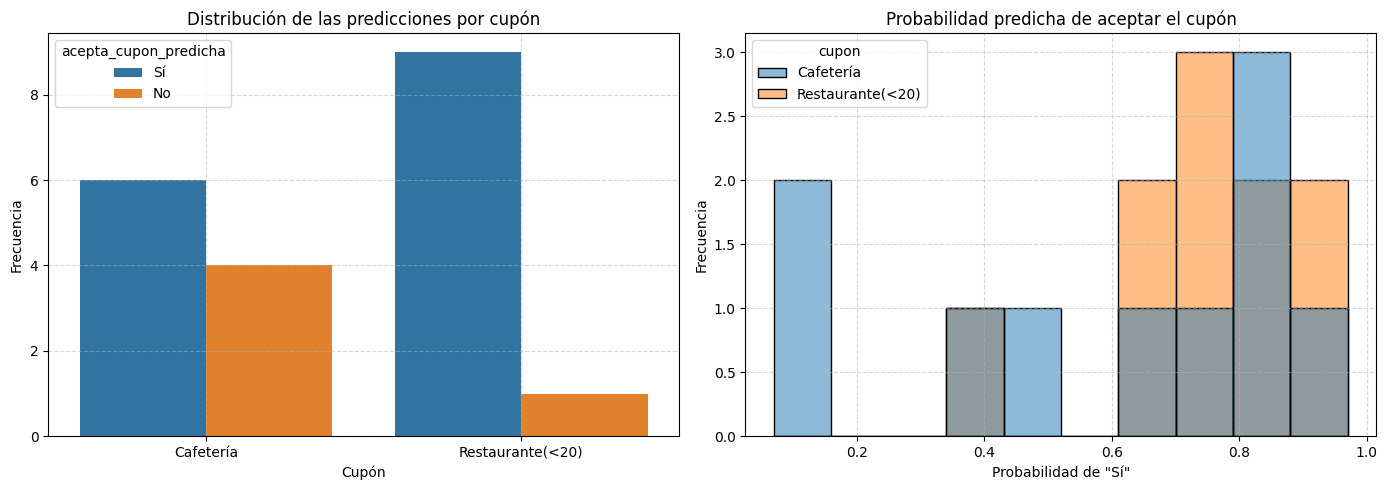

--- DISTRIBUCIÓN DE LAS PREDICCIONES (%) ---
acepta_cupon_predicha    No    Sí
cupon                            
Cafetería              40.0  60.0
Restaurante(<20)       10.0  90.0

--- RESUMEN DE LA PROBABILIDAD PREDICHA DE "SÍ" ---
                  count   mean    std   min    25%    50%    75%   max
cupon                                                                 
Cafetería          10.0  0.588  0.304  0.07  0.412  0.680  0.825  0.94
Restaurante(<20)   10.0  0.765  0.176  0.37  0.699  0.785  0.862  0.97


In [50]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribucion de las clases predichas por cupon
sns.countplot(data=test_data_final, x='cupon', hue='acepta_cupon_predicha', ax=axes[0])
axes[0].set_title('Distribución de las predicciones por cupón')
axes[0].set_xlabel('Cupón')
axes[0].set_ylabel('Frecuencia')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Probabilidad de aceptar el cupón asignada por el modelo
probabilidades = []
for cupon, modelo in mejores.items():
    mascara = df_test_copy['cupon'] == cupon
    X_nuevo = df_test_copy.loc[mascara].drop(columns=cols_eliminar)
    p = pd.Series(modelo.predict_proba(X_nuevo)[:, list(modelo.classes_).index('Sí')], index=X_nuevo.index)
    probabilidades.append(p)
test_data_final['prob_sí'] = pd.concat(probabilidades)

sns.histplot(data=test_data_final, x='prob_sí', hue='cupon', bins=10, ax=axes[1])
axes[1].set_title('Probabilidad predicha de aceptar el cupón')
axes[1].set_xlabel('Probabilidad de "Sí"')
axes[1].set_ylabel('Frecuencia')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Resumen estadístico de la validación
print('--- DISTRIBUCIÓN DE LAS PREDICCIONES (%) ---')
print((pd.crosstab(test_data_final['cupon'], test_data_final['acepta_cupon_predicha'], normalize='index') * 100).round(1))
print()
print('--- RESUMEN DE LA PROBABILIDAD PREDICHA DE "SÍ" ---')
print(test_data_final.groupby('cupon')['prob_sí'].describe().round(3))

test_data_final = test_data_final.drop(columns='prob_sí')

El archivo de prueba no tiene la variable objetivo real `acepta_cupon` por lo que la calidad de las predicciones no se pudo medir con F1 o recall:

1. Se tienen 20 filas en el archivo que son 10 por cupon y cada una recibo una prediccion, con esto el CSV conserva las 25 columnas originales mas `acepta_cupon_predicha`.

2. **Distribución de las clases predichas:**
   - Las predicciones se reparten de esta manera, cafeteria con 6 "Sí" y 4 "No" que es un 60% y 40%. Esto es cercano a la distribucion que se evidencion en el entrenamiento que es casi balanceada (49,9% "Sí" y 50,1% "No").
   - Para Restaurante(<20) se tienen 9 "Sí" y 1 "No" con 90% y 10%. Se predice mas "Sí" que el 70,7% del entrenamiento lo cual es coherente con lo visto en la prueba donde el Random Forest sin balanceo detecta pocos rechazos (recall de "No" de 0,42) y tiende a favorecer la clase mayoritaria. Ademas de esto 8 de las 10 filas de este cupon tienen como destino "Sin lugar urgente" que es la categoria con mayor aceptacion.

3. La consistencia con las variables mas importantes se mira de esta manera:
   - En cafeteria los "No" se concentran en conductores que van poco o nunca a cafeterias y en un caso con clima lluvioso y hora nocturna. Este es el comportamiento esperado ya que `frecuencia_cafeteria` es la variable dominante.

4. Por ulimo se tiene la limitacion de que con solo 20 registros cada fila cambia la distribucion en 10 puntos porcentuales por cupon. 

# 12. Video explicativo del laboratorio

https://youtu.be/1uEr72W237k

# 13. Uso de IA generativa

## 1. Declaración del uso
- **Herramienta:** Claude.
- **Tipo de uso:** ayuda conceptual, generación inicial de código , revisión y depuración de código, y asistencia de redacción para los análisis a partir de las ideas y resultados de los estudiantes. También se usó para revisar el notebook de exploración y preprocesamiento elaborado por los estudiantes y para apoyar el guion del video.

## 2. Prompts utilizados (resumidos)
1. Lectura del enunciado y resumen de lo que se debía entregar.
2. Revisión del notebook existente en distintos pasos del proceso para evluar el progreso.
3. Soporte en la redacción de párrafos a partir de las ideas sueltas proporcionadas por los estudiantes.
4. Revisión de código y generación de código en caso de errores.
5. Ayuda para resolver dudas conceptuales.  

## 3. Análisis crítico del resultado

**¿Qué decisiones técnicas fueron modificadas respecto a la respuesta de la IAG y por qué?** Las respuestas generadas por la IA no se tomaron tal cual: se revisaban contra lo visto en el curso. Cuando la respuesta incluía conceptos o técnicas que no se han trabajado en clase, se retiraban o se reemplazaban. Un ejemplo es el tipo de regularización de la regresión logística: se descartó `elasticnet` y la grilla se limitó a L1 y L2, que sí se vieron. En el sentido contrario, se incluyeron elementos del curso que la respuesta no mencionaba: por ejemplo, se pidió acompañar cada modelo con su matriz de confusión y su reporte de clasificación, como se hace en las prácticas, y se pidió explorar si existía una forma de ordenar las variables por su peso análoga a los coeficientes de la regresión lineal.

**¿Qué partes del contenido generado fueron correctas y útiles?** El código generado fue, en general, correcto y se ejecutó sin modificaciones sustanciales. Aun así, no se aceptó sin revisión: cada celda se ejecutó y sus resultados se contrastaron con lo esperado. Los pocos problemas fueron de ejecución, como filas repetidas en la tabla comparativa al volver a correr una celda, que se detectaron al revisar los resultados y se corrigieron.

**¿Qué conceptos del curso permitieron evaluar o mejorar la respuesta generada?** Los más importantes fueron las métricas de evaluación, en especial la diferencia entre exactitud y F1-score, porque esa fue una de las grandes cuestiones a resolver a lo largo del laboratorio. En Restaurante(<20) las clases están desbalanceadas (70,7 % acepta), de modo que un modelo que siempre responda "Sí" ya alcanza esa exactitud sin aprender nada. Este concepto permitió leer críticamente los resultados: justificó usar el F1 macro para seleccionar modelos, mirar el recall de la clase minoritaria y entender que la exactitud, por sí sola, hacía parecer buenos a modelos que detectaban muy pocos rechazos.

## 4. Aportes propios de los estudiantes

**Código.** El código se fue modificando para ajustarse a la comprensión de los estudiantes. La grilla de hiperparámetros, por ejemplo, se cambió en distintas iteraciones para buscar la mejor configuración (como con los valores de `C` en la regresión logística). Cuando las pruebas no mostraban una tendencia clara a favor de una alternativa, se mantuvo la propuesta original del modelo en lugar de cambiarla sin una razón.

**Análisis y explicaciones.** Los textos que acompañan al código se ajustaron para no depender de conceptos que no se hubieran mencionado en clase. Cuando se consideró que uno de esos conceptos 'nuevos' era fundamental para sustentar una conclusión, no se omitió: se profundizó en él hasta comprenderlo y poder explicarlo con las propias palabras de los estudiantes.

**Decisiones propias.** La conclusión sobre SMOTE fue de los estudiantes. No bastaba con ver que mejoraba el recall de la clase "No": había que precisar el trade-off (se detectan más rechazos, pero se etiquetan como rechazo conductores que sí habrían aceptado) y bajo qué condiciones convendría aplicarlo. Esa precisión, que Ruta Alpes solo debería aplicarlo si prioriza no mostrar ofertas a quien las va a rechazar, fue motivada por los estudiantes y no por la respuesta original de la IA.

**Aprendizaje.** La IA es una herramienta muy útil para agilizar el trabajo, pero no se debe dejar que lo haga por completo sin razonarlo: de lo contrario se llega a conclusiones que no se entienden o con las que no se está de acuerdo. El proceso mostró que el valor del trabajo estuvo en cuestionar cada resultado (si el modelo realmente mejoraba o solo cambiaba de tipo de error) y no en generar el código.